In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve
from scipy.signal import find_peaks
from scipy.linalg import eig
import matplotlib.colors as mcolors

# System definition (unchanged)
def predator_prey(t, x, alpha, beta, gamma, delta):
    x1, x2 = x
    denom = 1 + x1 + x1**2/alpha
    dx1dt = x1 * (1 - x1/gamma) - (x1 * x2) / denom
    dx2dt = beta * delta * (x1 * x2) / denom - delta * x2
    return [dx1dt, dx2dt]

def find_equilibria(alpha, beta, gamma, delta):
    equilibria = []
    equilibria.append((0, 0))  # Trivial
    equilibria.append((gamma, 0))  # Prey-only
    
    # Coexistence equilibrium
    def f(x1):
        return beta * x1 / (1 + x1 + x1**2/alpha) - 1
    
    x1_vals = np.linspace(0.1, gamma*1.5, 1000)
    for x1 in x1_vals:
        try:
            if abs(f(x1)) < 1e-6:
                x2 = x1 * (1 - x1/gamma) * (1 + x1 + x1**2/alpha) / x1
                if x2 > 0:
                    equilibria.append((x1, x2))
                    break
        except:
            continue
    
    return equilibria

def jacobian(x1, x2, alpha, beta, gamma, delta):
    denom = 1 + x1 + x1**2/alpha
    df1_dx1 = (1 - 2*x1/gamma) - (x2*(denom - x1*(1 + 2*x1/alpha)))/(denom**2)
    df1_dx2 = -x1/denom
    df2_dx1 = beta*delta*x2*(denom - x1*(1 + 2*x1/alpha))/(denom**2)
    df2_dx2 = beta*delta*x1/denom - delta
    return np.array([[df1_dx1, df1_dx2], [df2_dx1, df2_dx2]])

def detect_limit_cycle(alpha, beta, gamma, delta, initial_condition=None, t_span=(0, 2000)):
    if initial_condition is None:
        eq_points = find_equilibria(alpha, beta, gamma, delta)
        if len(eq_points) > 2:
            initial_condition = [eq_points[2][0] * 1.1, eq_points[2][1] * 1.1]
        else:
            initial_condition = [gamma * 0.8, 0.5]
    
    t_eval = np.linspace(t_span[0], t_span[1], 10000)
    sol = solve_ivp(predator_prey, t_span, initial_condition, 
                   args=(alpha, beta, gamma, delta),
                   t_eval=t_eval, method='LSODA', rtol=1e-8, atol=1e-10)
    
    final_indices = slice(-2000, None)
    final_x1 = sol.y[0][final_indices]
    final_x2 = sol.y[1][final_indices]
    
    std_x1 = np.std(final_x1)
    std_x2 = np.std(final_x2)
    is_oscillating = std_x1 > 0.01 and std_x2 > 0.01
    
    if is_oscillating:
        peaks_x1, _ = find_peaks(final_x1)
        period = np.mean(np.diff(sol.t[final_indices][peaks_x1])) if len(peaks_x1) > 1 else None
        
        limit_cycle_info = {
            'exists': True,
            'period': period,
            'amplitude': (np.ptp(final_x1), np.ptp(final_x2)),
            'center': (np.mean(final_x1), np.mean(final_x2)),
            'final_trajectory': (final_x1, final_x2),
            'full_solution': sol
        }
    else:
        limit_cycle_info = {'exists': False}
    
    return limit_cycle_info

/tmp/ipykernel_296175/670255517.py:45: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax1.legend()
/tmp/ipykernel_296175/670255517.py:56: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.legend()


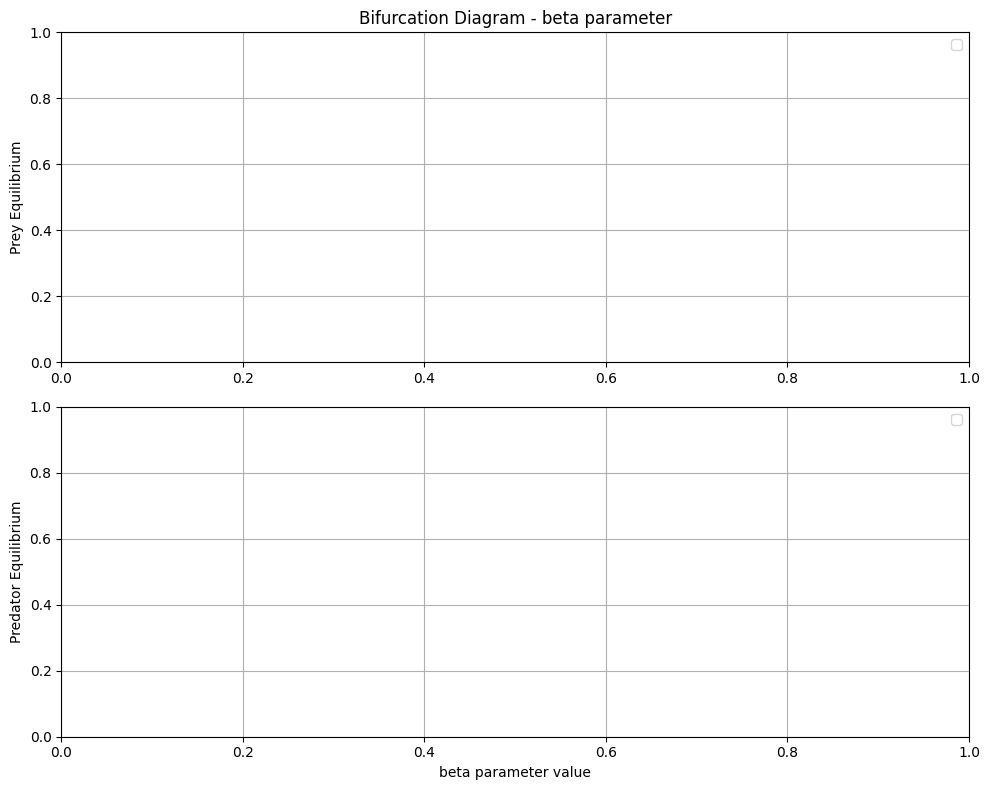

In [15]:
def plot_bifurcation_diagram(param_name, param_range, fixed_params, num_points=100):
    """Plot robust bifurcation diagram without legend issues"""
    
    param_vals = np.linspace(param_range[0], param_range[1], num_points)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
    
    prey_stable, prey_unstable = [], []
    predator_stable, predator_unstable = [], []
    param_stable, param_unstable = [], []
    
    for param_val in param_vals:
        params = fixed_params.copy()
        params[param_name] = param_val
        
        alpha = params.get('alpha', 2)
        beta = params.get('beta', 1.5)
        gamma = params.get('gamma', 3)
        delta = params.get('delta', 1)
        
        eq_points = find_equilibria(alpha, beta, gamma, delta)
        
        if len(eq_points) > 2:
            co_eq = eq_points[2]
            J = jacobian(co_eq[0], co_eq[1], alpha, beta, gamma, delta)
            eigenvalues = eig(J)[0]
            real_parts = eigenvalues.real
            
            if all(real_parts < 0):
                prey_stable.append(co_eq[0])
                predator_stable.append(co_eq[1])
                param_stable.append(param_val)
            else:
                prey_unstable.append(co_eq[0])
                predator_unstable.append(co_eq[1])
                param_unstable.append(param_val)
    
    # Plot prey bifurcation
    if param_stable:
        ax1.plot(param_stable, prey_stable, 'bo', markersize=4, label='Stable')
    if param_unstable:
        ax1.plot(param_unstable, prey_unstable, 'rx', markersize=4, label='Unstable')
    
    ax1.set_ylabel('Prey Equilibrium')
    ax1.set_title(f'Bifurcation Diagram - {param_name} parameter')
    ax1.legend()
    ax1.grid(True)
    
    # Plot predator bifurcation
    if param_stable:
        ax2.plot(param_stable, predator_stable, 'go', markersize=4, label='Stable')
    if param_unstable:
        ax2.plot(param_unstable, predator_unstable, 'mx', markersize=4, label='Unstable')
    
    ax2.set_ylabel('Predator Equilibrium')
    ax2.set_xlabel(f'{param_name} parameter value')
    ax2.legend()
    ax2.grid(True)
    
    plt.tight_layout()
    plt.show()

# Example usage
fixed_params = {'alpha': 2, 'gamma': 3, 'delta': 1}
plot_bifurcation_diagram('beta', [1.0, 4.0], fixed_params)

In [16]:
def identify_bifurcation_types():
    """Identify and display different bifurcation types"""
    
    print("=== BIFURCATION TYPE IDENTIFICATION ===")
    
    # Test cases for different bifurcations
    test_cases = [
        ("Transcritical", (2, 1.4, 3, 1), (2, 1.6, 3, 1)),
        ("Hopf", (2, 2.8, 3, 1), (2, 3.2, 3, 1)),
        ("Stable", (4, 2.0, 3, 1), (4, 2.0, 3, 1)),
        ("Limit Cycle", (6, 2.2, 3, 1), (6, 2.2, 3, 1)),
    ]
    
    for bif_type, params_before, params_after in test_cases:
        print(f"\n--- {bif_type} Bifurcation ---")
        
        alpha_b, beta_b, gamma_b, delta_b = params_before
        alpha_a, beta_a, gamma_a, delta_a = params_after
        
        # Before bifurcation
        eq_before = find_equilibria(alpha_b, beta_b, gamma_b, delta_b)
        print(f"Before: α={alpha_b}, β={beta_b}")
        print(f"  Equilibria: {eq_before}")
        
        if len(eq_before) > 2:
            J_before = jacobian(eq_before[2][0], eq_before[2][1], alpha_b, beta_b, gamma_b, delta_b)
            eig_before = eig(J_before)[0]
            print(f"  Eigenvalues: {eig_before[0]:.3f}, {eig_before[1]:.3f}")
        
        # After bifurcation
        eq_after = find_equilibria(alpha_a, beta_a, gamma_a, delta_a)
        print(f"After: α={alpha_a}, β={beta_a}")
        print(f"  Equilibria: {eq_after}")
        
        if len(eq_after) > 2:
            J_after = jacobian(eq_after[2][0], eq_after[2][1], alpha_a, beta_a, gamma_a, delta_a)
            eig_after = eig(J_after)[0]
            print(f"  Eigenvalues: {eig_after[0]:.3f}, {eig_after[1]:.3f}")
        
        # Detect limit cycle
        lc_info = detect_limit_cycle(alpha_a, beta_a, gamma_a, delta_a)
        if lc_info['exists']:
            print(f"  Limit cycle detected! Period: {lc_info.get('period', 'N/A'):.2f}")

# Run identification
identify_bifurcation_types()

=== BIFURCATION TYPE IDENTIFICATION ===

--- Transcritical Bifurcation ---
Before: α=2, β=1.4
  Equilibria: [(0, 0), (3, 0)]
After: α=2, β=1.6
  Equilibria: [(0, 0), (3, 0)]

--- Hopf Bifurcation ---
Before: α=2, β=2.8
  Equilibria: [(0, 0), (3, 0)]
After: α=2, β=3.2
  Equilibria: [(0, 0), (3, 0)]
  Limit cycle detected! Period: 27.76

--- Stable Bifurcation ---
Before: α=4, β=2.0
  Equilibria: [(0, 0), (3, 0), (np.float64(1.9982982982982984), np.float64(1.3344661123350507))]
  Eigenvalues: -0.332+0.000j, -0.000+0.000j
After: α=4, β=2.0
  Equilibria: [(0, 0), (3, 0), (np.float64(1.9982982982982984), np.float64(1.3344661123350507))]
  Eigenvalues: -0.332+0.000j, -0.000+0.000j

--- Limit Cycle Bifurcation ---
Before: α=6, β=2.2
  Equilibria: [(0, 0), (3, 0)]
After: α=6, β=2.2
  Equilibria: [(0, 0), (3, 0)]
  Limit cycle detected! Period: 14.65


In [17]:
def explore_parameter_space():
    """Simple parameter exploration without complex plotting"""
    
    print("=== PARAMETER SPACE EXPLORATION ===")
    
    # Test different parameter combinations
    parameters = [
        (2, 2.0, 3, 1),  # Stable
        (2, 3.0, 3, 1),  # Hopf region
        (2, 3.5, 3, 1),  # Limit cycle
        (4, 2.0, 3, 1),  # Different alpha
        (4, 2.5, 3, 1),  # Another limit cycle
        (6, 2.0, 3, 1),  # High alpha
        (6, 2.3, 3, 1),  # Limit cycle with high alpha
    ]
    
    for alpha, beta, gamma, delta in parameters:
        print(f"\nα={alpha}, β={beta}, γ={gamma}, δ={delta}:")
        
        eq_points = find_equilibria(alpha, beta, gamma, delta)
        print(f"  Equilibria: {len(eq_points)} points")
        
        if len(eq_points) > 2:
            co_eq = eq_points[2]
            J = jacobian(co_eq[0], co_eq[1], alpha, beta, gamma, delta)
            eigenvalues = eig(J)[0]
            real_parts = eigenvalues.real
            
            if all(real_parts < 0):
                print("  Stable equilibrium")
            else:
                print("  Unstable equilibrium")
                print(f"  Eigenvalues: {eigenvalues[0]:.3f}, {eigenvalues[1]:.3f}")
                
                # Check for limit cycle
                lc_info = detect_limit_cycle(alpha, beta, gamma, delta)
                if lc_info['exists']:
                    print("  ✓ Limit cycle present")
                else:
                    print("  ✗ No limit cycle")

# Run exploration
explore_parameter_space()

=== PARAMETER SPACE EXPLORATION ===

α=2, β=2.0, γ=3, δ=1:
  Equilibria: 2 points

α=2, β=3.0, γ=3, δ=1:
  Equilibria: 2 points

α=2, β=3.5, γ=3, δ=1:
  Equilibria: 2 points

α=4, β=2.0, γ=3, δ=1:
  Equilibria: 3 points
  Stable equilibrium

α=4, β=2.5, γ=3, δ=1:
  Equilibria: 2 points

α=6, β=2.0, γ=3, δ=1:
  Equilibria: 2 points

α=6, β=2.3, γ=3, δ=1:
  Equilibria: 2 points


In [18]:
def prey_nullcline(x1, alpha, beta, gamma, delta):
    """Prey nullcline: dx1/dt = 0"""
    # From dx1/dt = 0: x1(1 - x1/γ) - (x1x₂)/(1 + x1 + x1²/α) = 0
    # Solve for x2: x2 = (1 - x1/γ) * (1 + x1 + x1²/α)
    return (1 - x1/gamma) * (1 + x1 + x1**2/alpha)

def predator_nullcline(x1, alpha, beta, gamma, delta):
    """Predator nullcline: dx2/dt = 0"""
    # From dx2/dt = 0: βδ(x1x₂)/(1 + x1 + x1²/α) - δx2 = 0
    # Solutions: x2 = 0 or βx1/(1 + x1 + x1²/α) = 1
    # For non-trivial case: x1 where βx1/(1 + x1 + x1²/α) = 1
    # This gives the vertical line x1 = x1* such that the functional response equals 1/β
    return None  # This is a vertical line, we'll handle it separately

def find_predator_nullcline_x1(alpha, beta):
    """Find the x1 value where predator nullcline occurs"""
    # Solve: βx1/(1 + x1 + x1²/α) = 1
    # Rearranged: βx1 = 1 + x1 + x1²/α
    # => x1²/α + x1(1 - β) + 1 = 0
    
    # Quadratic equation: (1/α)x1² + (1-β)x1 + 1 = 0
    a = 1/alpha
    b = 1 - beta
    c = 1
    
    discriminant = b**2 - 4*a*c
    
    if discriminant >= 0:
        x1_1 = (-b + np.sqrt(discriminant)) / (2*a)
        x1_2 = (-b - np.sqrt(discriminant)) / (2*a)
        # Return the positive real solution
        solutions = [x for x in [x1_1, x1_2] if x > 0 and np.isreal(x)]
        return solutions[0] if solutions else None
    return None

In [27]:
def plot_nullclines_with_bifurcation(alpha, beta, gamma, delta, x1_range=None, x2_range=None):
    """Plot nullclines and analyze bifurcations"""
    
    if x1_range is None:
        x1_range = [-1, gamma * 1.5]
    if x2_range is None:
        x2_range = [-1, 5]
    
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Generate x1 values for plotting
    x1_vals = np.linspace(max(0.01, x1_range[0]), x1_range[1], 1000)
    
    # Plot prey nullcline (dx1/dt = 0)
    x2_prey = prey_nullcline(x1_vals, alpha, beta, gamma, delta)
    ax.plot(x1_vals, x2_prey, 'b-', linewidth=3, label='Prey Nullcline (dx₁/dt=0)')
    
    # Plot predator nullcline (dx2/dt = 0)
    predator_x1 = find_predator_nullcline_x1(alpha, beta)
    if predator_x1 is not None and predator_x1 <= x1_range[1]:
        ax.axvline(x=predator_x1, color='r', linestyle='-', linewidth=3, 
                  label='Predator Nullcline (dx₂/dt=0)')
    
    # Plot x2=0 nullcline (predator extinction)
    ax.axhline(y=0, color='orange', linestyle='--', linewidth=2, 
              label='Predator Extinction (x₂=0)')
    
    # Find and plot equilibria (intersections of nullclines)
    eq_points = find_equilibria(alpha, beta, gamma, delta)
    
    stable_eq, unstable_eq = [], []
    for eq in eq_points:
        if eq[0] >= 0 and eq[1] >= 0:
            J = jacobian(eq[0], eq[1], alpha, beta, gamma, delta)
            eigenvalues = eig(J)[0]
            real_parts = eigenvalues.real
            
            if all(real_parts < 0):
                stable_eq.append(eq)
                ax.plot(eq[0], eq[1], 'go', markersize=12, markerfacecolor='green', 
                       markeredgewidth=2, label='Stable Equilibrium')
            else:
                unstable_eq.append(eq)
                ax.plot(eq[0], eq[1], 'ro', markersize=12, markerfacecolor='red', 
                       markeredgewidth=2, label='Unstable Equilibrium')
    
    # Plot vector field
    x1_grid = np.linspace(x1_range[0], x1_range[1], 20)
    x2_grid = np.linspace(x2_range[0], x2_range[1], 20)
    X1, X2 = np.meshgrid(x1_grid, x2_grid)
    
    U, V = np.zeros(X1.shape), np.zeros(X2.shape)
    for i in range(len(x1_grid)):
        for j in range(len(x2_grid)):
            derivatives = predator_prey(0, [X1[i,j], X2[i,j]], alpha, beta, gamma, delta)
            U[i,j] = derivatives[0]
            V[i,j] = derivatives[1]
    
    # Normalize arrows for better visualization
    magnitude = np.sqrt(U**2 + V**2)
    U_norm = np.where(magnitude > 0, U/magnitude, 0)
    V_norm = np.where(magnitude > 0, V/magnitude, 0)
    
    ax.quiver(X1, X2, U_norm, V_norm, color='gray', alpha=0.6, scale=25)
    
    # Bifurcation analysis
    bifurcation_info = analyze_bifurcation_from_nullclines(alpha, beta, gamma, delta, eq_points)
    
    ax.set_xlabel('Prey Population (x₁)')
    ax.set_ylabel('Predator Population (x₂)')
    ax.set_title(f'Nullclines and Equilibria\nα={alpha}, β={beta}, γ={gamma}, δ={delta}\n{bifurcation_info}')
    ax.set_xlim(x1_range)
    ax.set_ylim(x2_range)
    ax.grid(True, alpha=0.3)
    
    # Remove duplicate labels in legend
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(), loc='upper right')
    
    plt.tight_layout()
    plt.show()
    
    return bifurcation_info

def analyze_bifurcation_from_nullclines(alpha, beta, gamma, delta, eq_points):
    """Analyze bifurcation type from nullcline configuration"""
    
    # Check for transcritical bifurcation (predator extinction)
    beta_critical = 1 + 1/alpha
    if abs(beta - beta_critical) < 0.1:
        return "Transcritical Bifurcation: Predator extinction boundary"
    
    # Check for Hopf bifurcation
    if len(eq_points) > 2:
        co_eq = eq_points[2]
        J = jacobian(co_eq[0], co_eq[1], alpha, beta, gamma, delta)
        eigenvalues = eig(J)[0]
        real_parts = eigenvalues.real
        
        # Hopf condition: complex eigenvalues crossing imaginary axis
        if (np.max(real_parts) > -1e-6 and np.min(real_parts) < 1e-6 and 
            any(abs(eig.imag) > 1e-6 for eig in eigenvalues)):
            return "Hopf Bifurcation: Stable → Unstable + Limit Cycle"
        
        if all(r < 0):
            return "Stable Equilibrium"
        else:
            return "Unstable Equilibrium"
    
    return "No Coexistence Equilibrium"

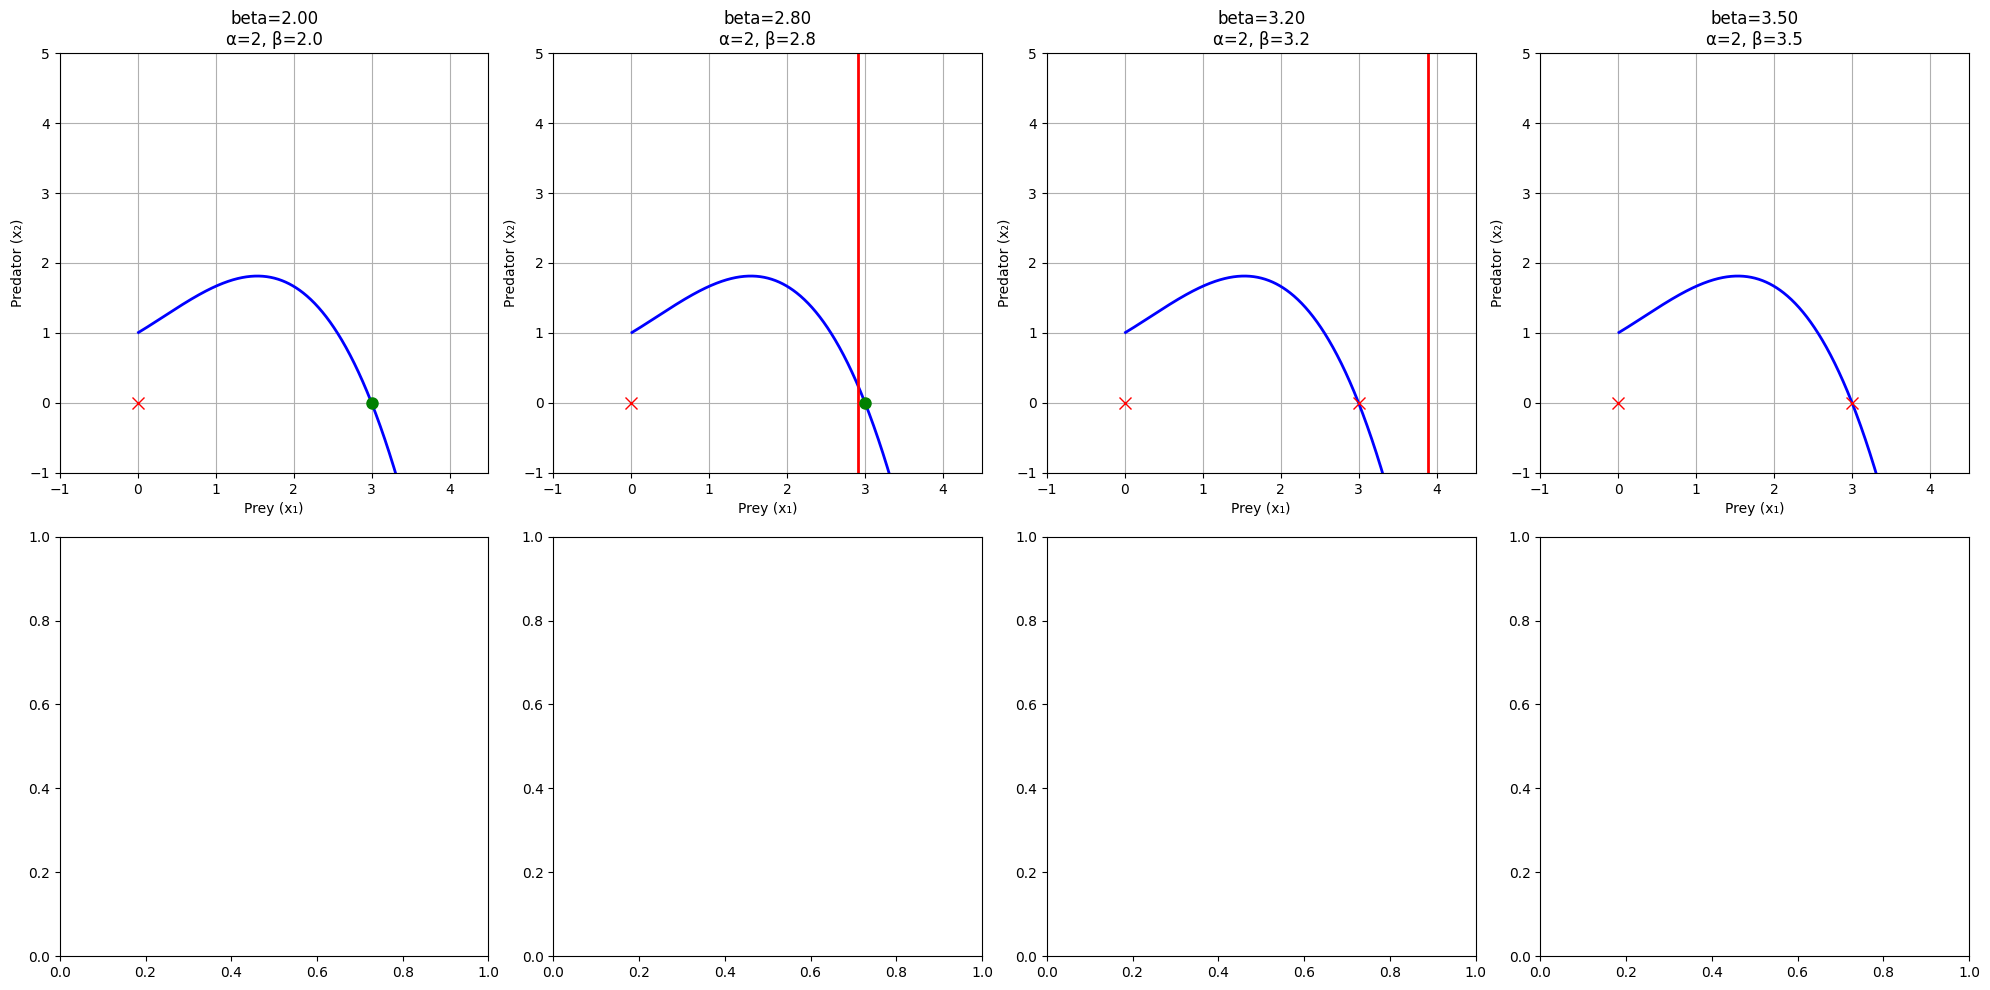

In [28]:
def plot_bifurcation_sequence_with_nullclines(param_name, param_values, fixed_params):
    """Show how nullclines change during bifurcation"""
    
    n = len(param_values)
    fig, axes = plt.subplots(2, n, figsize=(5*n, 10))
    
    if n == 1:
        axes = [[axes[0]], [axes[1]]]
    
    for i, param_val in enumerate(param_values):
        params = fixed_params.copy()
        params[param_name] = param_val
        
        alpha = params.get('alpha', 2)
        beta = params.get('beta', 1.5)
        gamma = params.get('gamma', 3)
        delta = params.get('delta', 1)
        
        # Top row: Phase portrait with nullclines
        x1_range = [-1, gamma * 1.5]
        x2_range = [-1, 5]
        
        x1_vals = np.linspace(0.01, x1_range[1], 1000)
        
        # Prey nullcline
        x2_prey = prey_nullcline(x1_vals, alpha, beta, gamma, delta)
        axes[0][i].plot(x1_vals, x2_prey, 'b-', linewidth=2, label='Prey Nullcline')
        
        # Predator nullcline
        predator_x1 = find_predator_nullcline_x1(alpha, beta)
        if predator_x1 is not None:
            axes[0][i].axvline(x=predator_x1, color='r', linestyle='-', linewidth=2, 
                              label='Predator Nullcline')
        
        # Equilibria
        eq_points = find_equilibria(alpha, beta, gamma, delta)
        for eq in eq_points:
            if eq[0] >= 0 and eq[1] >= 0:
                J = jacobian(eq[0], eq[1], alpha, beta, gamma, delta)
                eigenvalues = eig(J)[0]
                real_parts = eigenvalues.real
                
                color = 'green' if all(real_parts < 0) else 'red'
                marker = 'o' if all(real_parts < 0) else 'x'
                axes[0][i].plot(eq[0], eq[1], marker, color=color, markersize=8, 
                               markerfacecolor=color)
        
        axes[0][i].set_xlabel('Prey (x₁)')
        axes[0][i].set_ylabel('Predator (x₂)')
        axes[0][i].set_title(f'{param_name}={param_val:.2f}\nα={alpha}, β={beta}')
        axes[0][i].set_xlim(x1_range)
        axes[0][i].set_ylim(x2_range)
        axes[0][i].grid(True)
        
        # Bottom row: Time series
        if len(eq_points) > 2:
            x0 = [eq_points[2][0]*1.1, eq_points[2][1]*1.1]
            t_span = (0, 200)
            t_eval = np.linspace(0, 200, 1000)
            
            sol = solve_ivp(predator_prey, t_span, x0, 
                           args=(alpha, beta, gamma, delta),
                           t_eval=t_eval, method='LSODA')
            
            axes[1][i].plot(sol.t, sol.y[0], 'b-', label='Prey')
            axes[1][i].plot(sol.t, sol.y[1], 'r-', label='Predator')
            axes[1][i].set_xlabel('Time')
            axes[1][i].set_ylabel('Population')
            axes[1][i].legend()
            axes[1][i].grid(True)
    
    plt.tight_layout()
    plt.show()

# Example: Show nullcline changes during Hopf bifurcation
fixed_params = {'alpha': 2, 'gamma': 3, 'delta': 1}
beta_values = [2.0, 2.8, 3.2, 3.5]  # Stable → Hopf → Limit cycle
plot_bifurcation_sequence_with_nullclines('beta', beta_values, fixed_params)

/tmp/ipykernel_296175/321234215.py:43: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('viridis', 3)


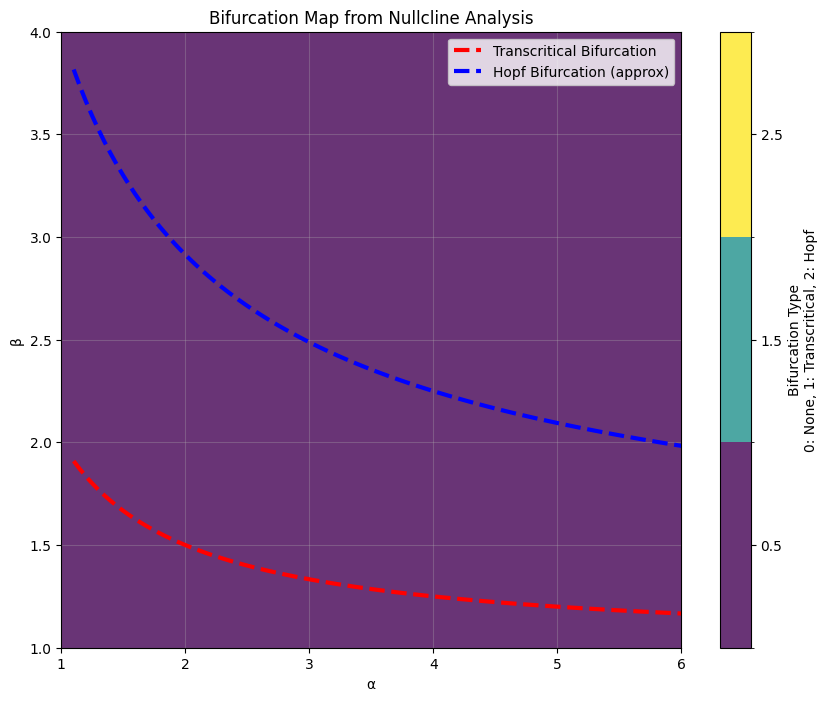

In [29]:
def detect_bifurcations_from_nullclines(alpha_range=(1, 6), beta_range=(1, 4), gamma=3, delta=1, resolution=20):
    """Detect bifurcations by analyzing nullcline intersections"""
    
    alpha_vals = np.linspace(alpha_range[0], alpha_range[1], resolution)
    beta_vals = np.linspace(beta_range[0], beta_range[1], resolution)
    
    bifurcation_map = np.zeros((resolution, resolution))  # 0: no bifurcation, 1: transcritical, 2: hopf
    
    for i, alpha in enumerate(alpha_vals):
        for j, beta in enumerate(beta_vals):
            # Find predator nullcline position
            predator_x1 = find_predator_nullcline_x1(alpha, beta)
            
            if predator_x1 is None:
                continue
                
            # Find prey nullcline at predator nullcline position
            prey_x2 = prey_nullcline(predator_x1, alpha, beta, gamma, delta)
            
            # Check if this is an equilibrium point
            eq_points = find_equilibria(alpha, beta, gamma, delta)
            
            if len(eq_points) > 2:
                co_eq = eq_points[2]
                J = jacobian(co_eq[0], co_eq[1], alpha, beta, gamma, delta)
                eigenvalues = eig(J)[0]
                real_parts = eigenvalues.real
                
                # Check for Hopf bifurcation
                if (np.max(real_parts) > -1e-6 and np.min(real_parts) < 1e-6 and 
                    any(abs(eig.imag) > 1e-6 for eig in eigenvalues)):
                    bifurcation_map[i, j] = 2  # Hopf
                
                # Check for transcritical (predator extinction boundary)
                beta_critical = 1 + 1/alpha
                if abs(beta - beta_critical) < 0.1:
                    bifurcation_map[i, j] = 1  # Transcritical
    
    # Plot bifurcation map
    plt.figure(figsize=(10, 8))
    
    # Create custom colormap
    cmap = plt.cm.get_cmap('viridis', 3)
    bounds = [0, 1, 2, 3]
    norm = mcolors.BoundaryNorm(bounds, cmap.N)
    
    plt.imshow(bifurcation_map.T, extent=[alpha_range[0], alpha_range[1], 
                                       beta_range[0], beta_range[1]],
              origin='lower', aspect='auto', cmap=cmap, norm=norm, alpha=0.8)
    
    # Add theoretical curves
    alpha_theory = np.linspace(alpha_range[0] + 0.1, alpha_range[1], 100)
    beta_transcritical = 1 + 1/alpha_theory
    plt.plot(alpha_theory, beta_transcritical, 'r--', linewidth=3, 
            label='Transcritical Bifurcation')
    
    # Approximate Hopf curve (this would need more sophisticated calculation)
    beta_hopf_approx = 1 + 2/np.sqrt(alpha_theory) + 1/alpha_theory
    plt.plot(alpha_theory, beta_hopf_approx, 'b--', linewidth=3, 
            label='Hopf Bifurcation (approx)')
    
    plt.xlabel('α')
    plt.ylabel('β')
    plt.title('Bifurcation Map from Nullcline Analysis')
    plt.colorbar(ticks=[0.5, 1.5, 2.5], label='Bifurcation Type\n0: None, 1: Transcritical, 2: Hopf')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
    
    return bifurcation_map

# Create bifurcation map
bifurcation_map = detect_bifurcations_from_nullclines()


=== Stable Focus ===
Parameters: α=2, β=2.0, γ=3, δ=1


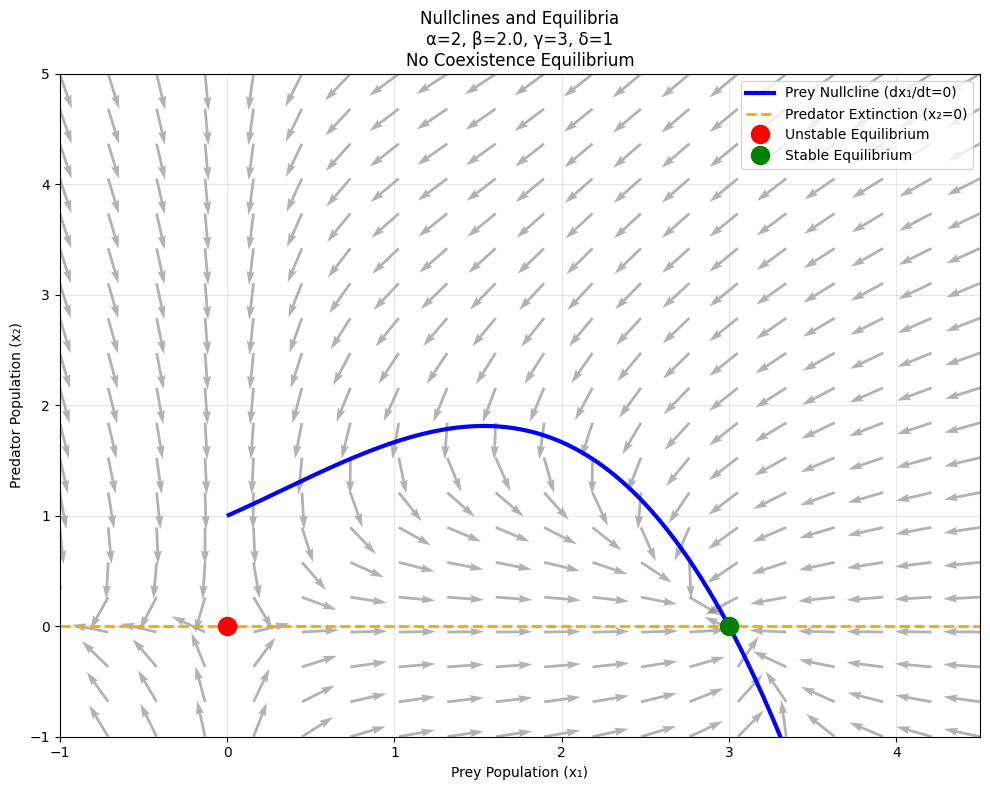

Bifurcation type: No Coexistence Equilibrium

=== Near Hopf ===
Parameters: α=2, β=2.9, γ=3, δ=1
Nullcline intersection at: x1=3.169, x2=-0.517


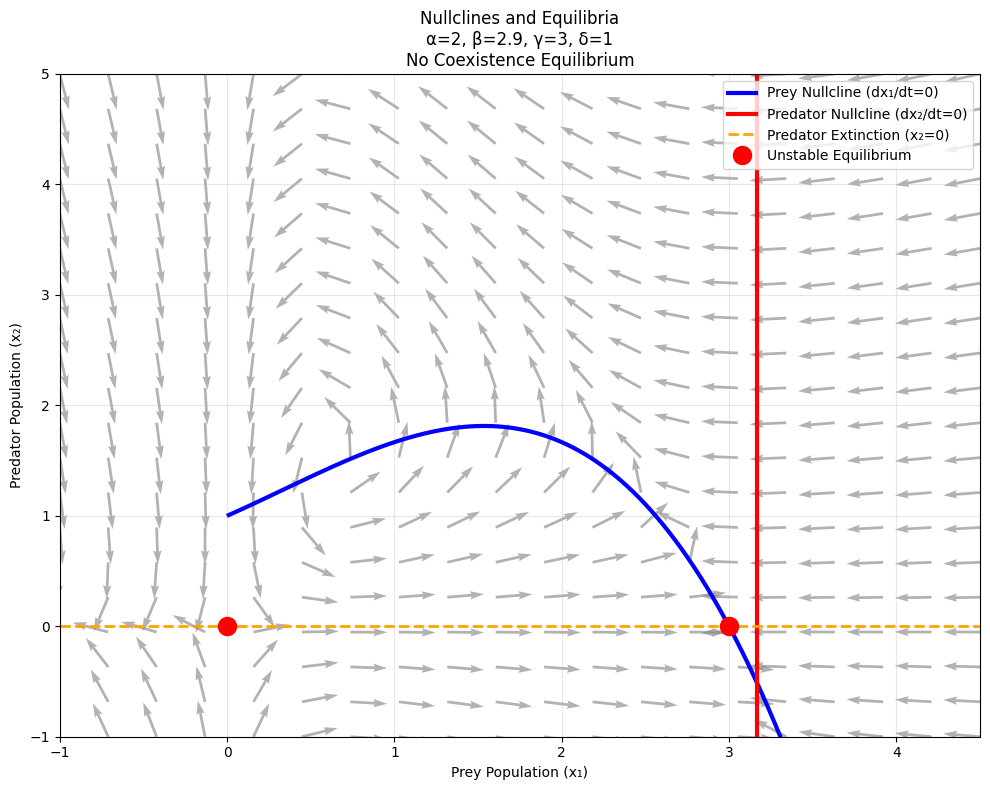

Bifurcation type: No Coexistence Equilibrium

=== Hopf Bifurcation ===
Parameters: α=2, β=3.0, γ=3, δ=1
Nullcline intersection at: x1=3.414, x2=-1.414


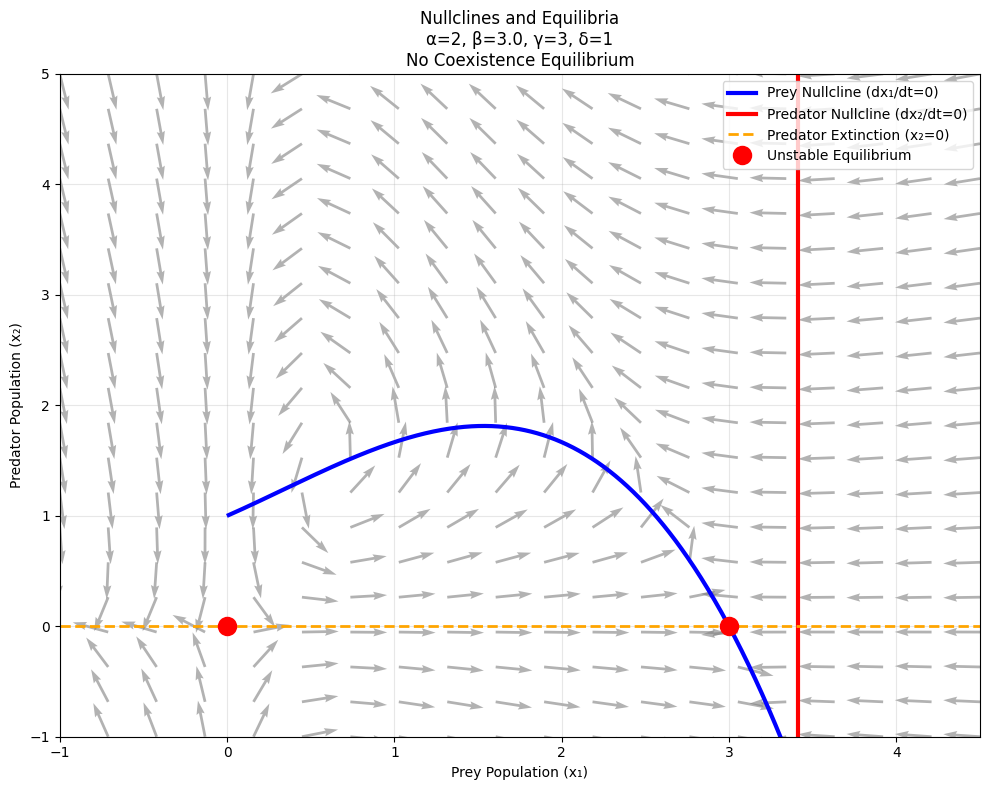

Bifurcation type: No Coexistence Equilibrium

=== Limit Cycle ===
Parameters: α=2, β=3.2, γ=3, δ=1
Nullcline intersection at: x1=3.885, x2=-3.669


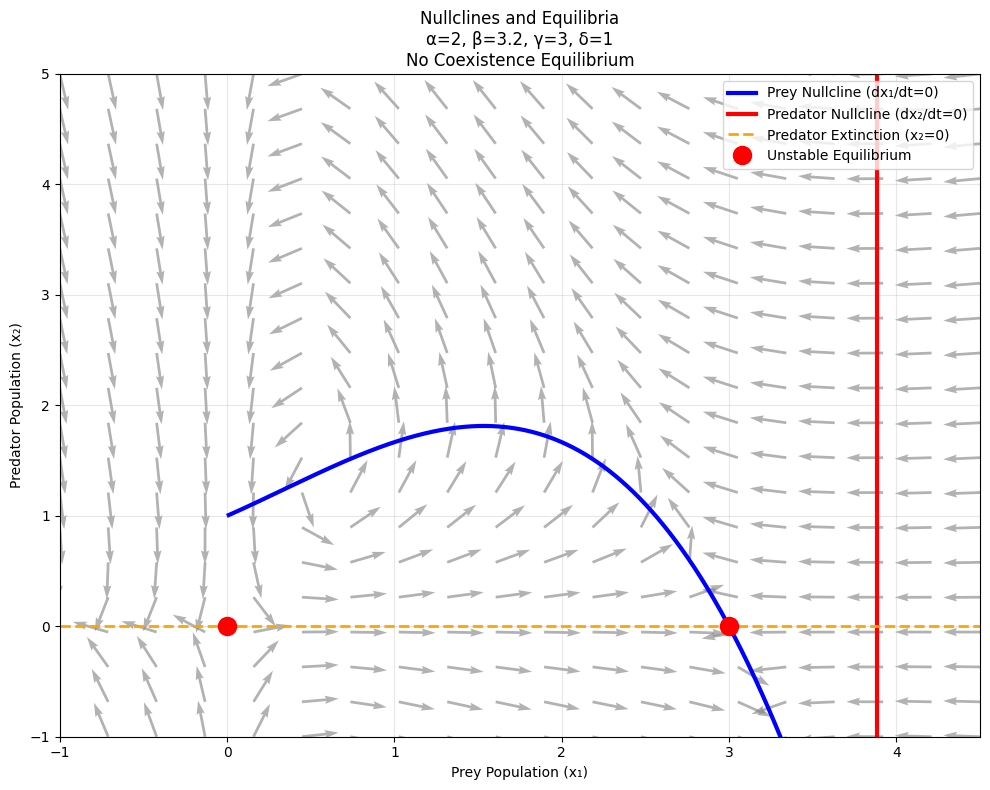

Bifurcation type: No Coexistence Equilibrium

=== Transcritical ===
Parameters: α=2, β=1.5, γ=3, δ=1


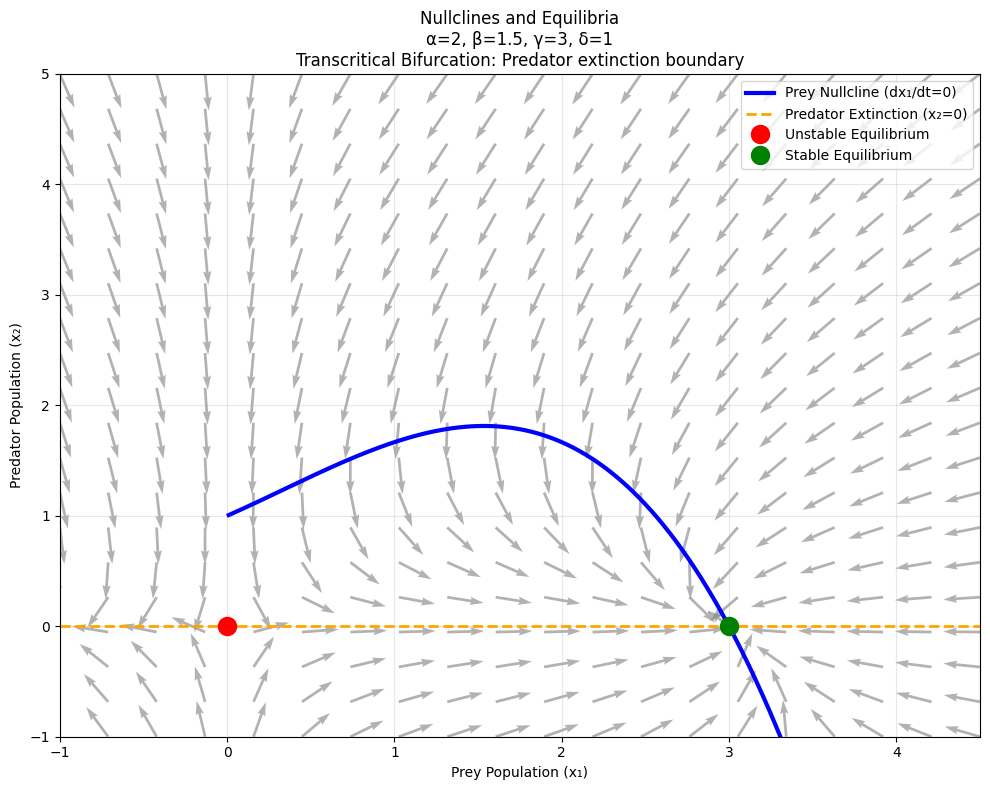

Bifurcation type: Transcritical Bifurcation: Predator extinction boundary

=== High Alpha ===
Parameters: α=6, β=2.0, γ=3, δ=1
Nullcline intersection at: x1=4.732, x2=-5.464


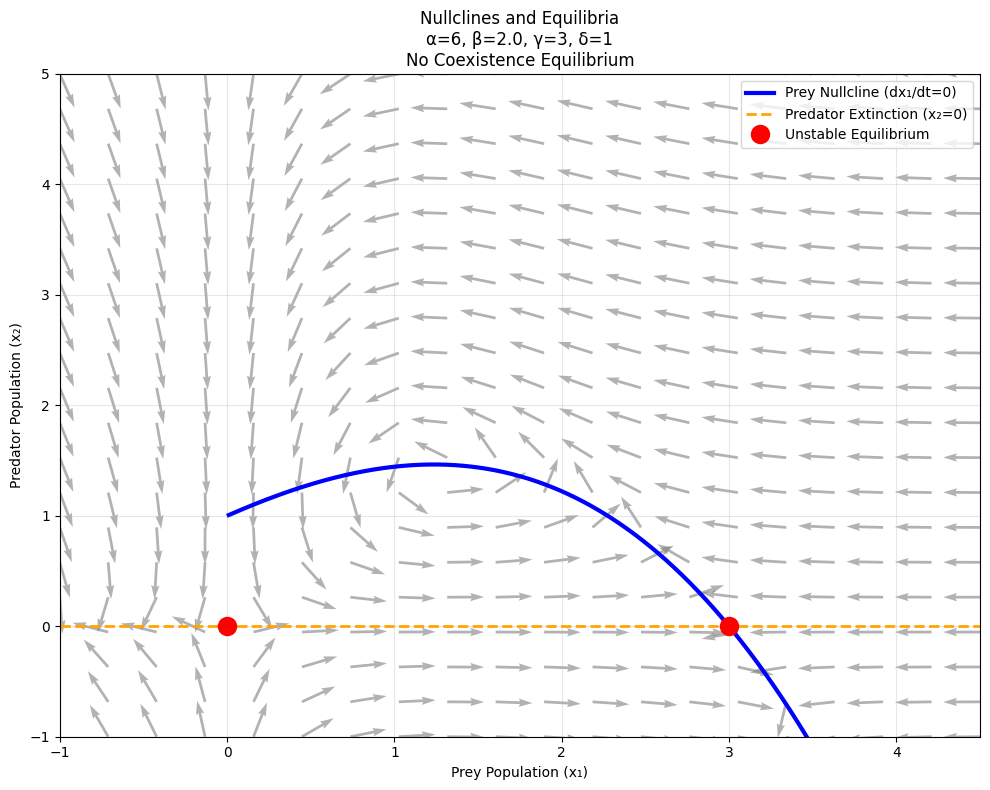

Bifurcation type: No Coexistence Equilibrium


In [30]:
def interactive_nullcline_exploration():
    """Interactive exploration of different bifurcation scenarios"""
    
    scenarios = [
        ("Stable Focus", (2, 2.0, 3, 1)),
        ("Near Hopf", (2, 2.9, 3, 1)),
        ("Hopf Bifurcation", (2, 3.0, 3, 1)),
        ("Limit Cycle", (2, 3.2, 3, 1)),
        ("Transcritical", (2, 1.5, 3, 1)),
        ("High Alpha", (6, 2.0, 3, 1)),
    ]
    
    for name, params in scenarios:
        alpha, beta, gamma, delta = params
        print(f"\n=== {name} ===")
        print(f"Parameters: α={alpha}, β={beta}, γ={gamma}, δ={delta}")
        
        # Analyze nullclines
        predator_x1 = find_predator_nullcline_x1(alpha, beta)
        if predator_x1:
            prey_x2 = prey_nullcline(predator_x1, alpha, beta, gamma, delta)
            print(f"Nullcline intersection at: x1={predator_x1:.3f}, x2={prey_x2:.3f}")
        
        # Plot with detailed analysis
        bifurcation_info = plot_nullclines_with_bifurcation(alpha, beta, gamma, delta)
        print(f"Bifurcation type: {bifurcation_info}")
        
        # Additional analysis
        eq_points = find_equilibria(alpha, beta, gamma, delta)
        if len(eq_points) > 2:
            co_eq = eq_points[2]
            J = jacobian(co_eq[0], co_eq[1], alpha, beta, gamma, delta)
            eigenvalues = eig(J)[0]
            print(f"Eigenvalues: {eigenvalues[0]:.3f}, {eigenvalues[1]:.3f}")

# Run interactive exploration
interactive_nullcline_exploration()

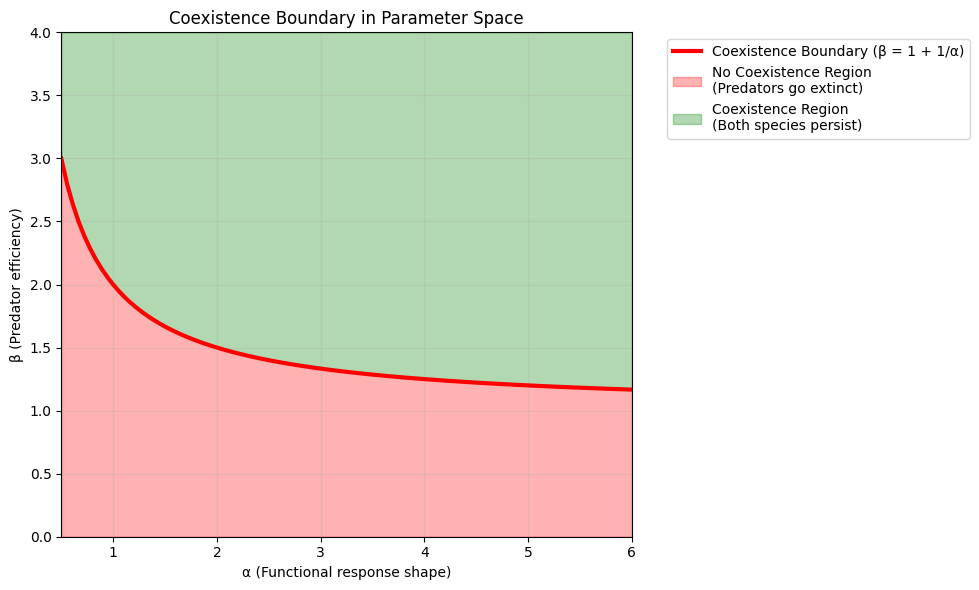

In [34]:
def plot_coexistence_boundary():
    """Plot the boundary between coexistence and no-coexistence regions"""
    
    # Create parameter grid
    alpha_vals = np.linspace(0.5, 6, 100)
    beta_critical_vals = 1 + 1/alpha_vals
    
    plt.figure(figsize=(10, 6))
    
    # Plot critical boundary
    plt.plot(alpha_vals, beta_critical_vals, 'r-', linewidth=3, 
             label='Coexistence Boundary (β = 1 + 1/α)')
    
    # Fill regions
    plt.fill_between(alpha_vals, 0, beta_critical_vals, alpha=0.3, color='red',
                    label='No Coexistence Region\n(Predators go extinct)')
    plt.fill_between(alpha_vals, beta_critical_vals, 4, alpha=0.3, color='green',
                    label='Coexistence Region\n(Both species persist)')
    
    # Mark some example points
    # example_points = [
    #     (2, 1.2, '✗ No coexistence', 'ro'),
    #     (2, 2.0, '✓ Coexistence', 'go'),
    #     (4, 1, '✗ No coexistence', 'ro'),
    #     (4, 2.5, '✓ Coexistence', 'go'),
    #     (6, 0.9, '✗ No coexistence', 'ro'),
    #     (6, 2.0, '✓ Coexistence', 'go'),
    # ]
    
    # for alpha, beta, label, style in example_points:
    #     plt.plot(alpha, beta, style, markersize=8, label=label)
    
    plt.xlabel('α (Functional response shape)')
    plt.ylabel('β (Predator efficiency)')
    plt.title('Coexistence Boundary in Parameter Space')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.xlim(0.5, 6)
    plt.ylim(0, 4)
    plt.tight_layout()
    plt.show()

# Plot the coexistence boundary
plot_coexistence_boundary()

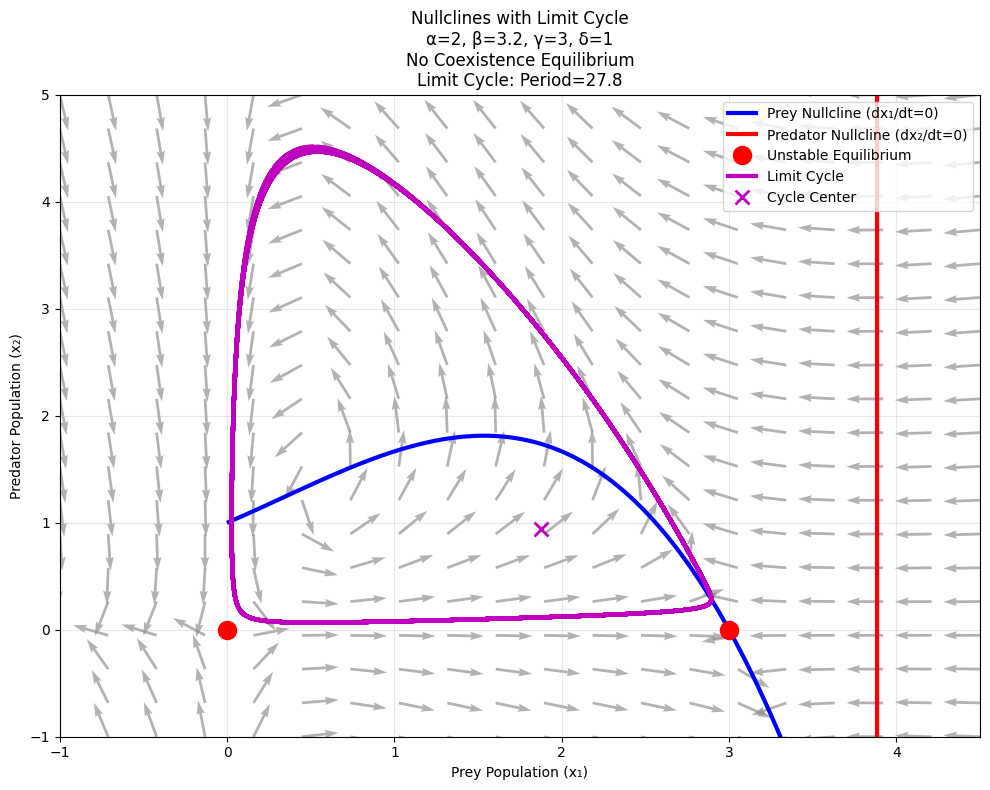

α=2, β=3.2: No Coexistence Equilibrium
  Limit cycle period: 27.76
--------------------------------------------------


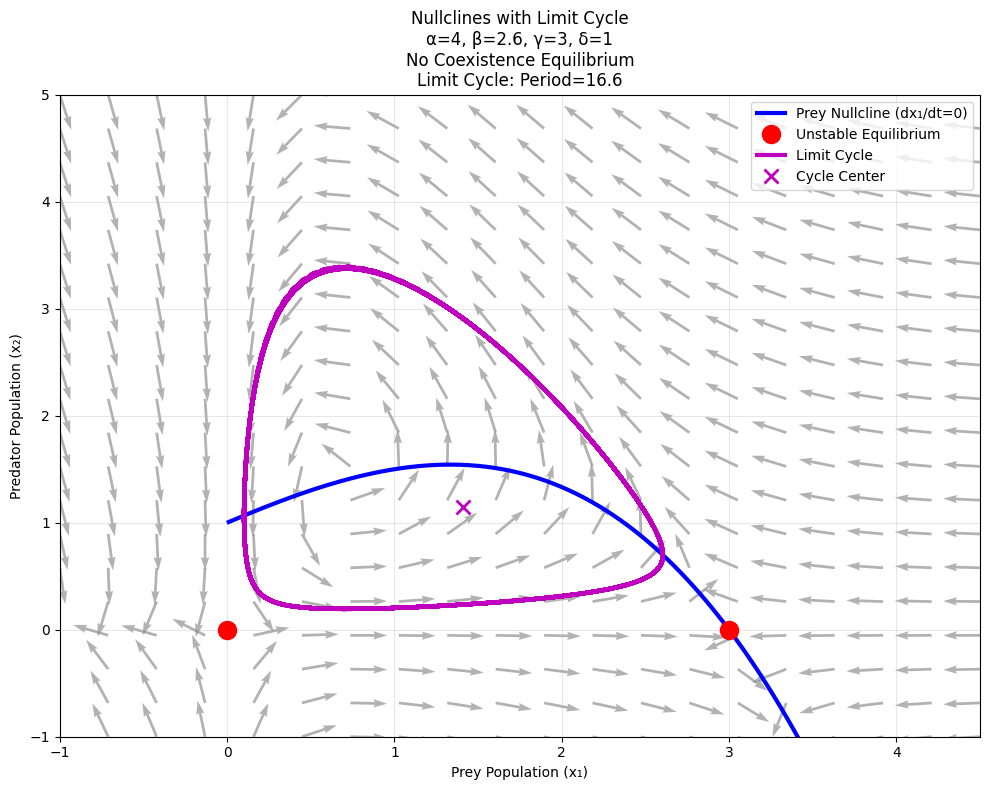

α=4, β=2.6: No Coexistence Equilibrium
  Limit cycle period: 16.60
--------------------------------------------------


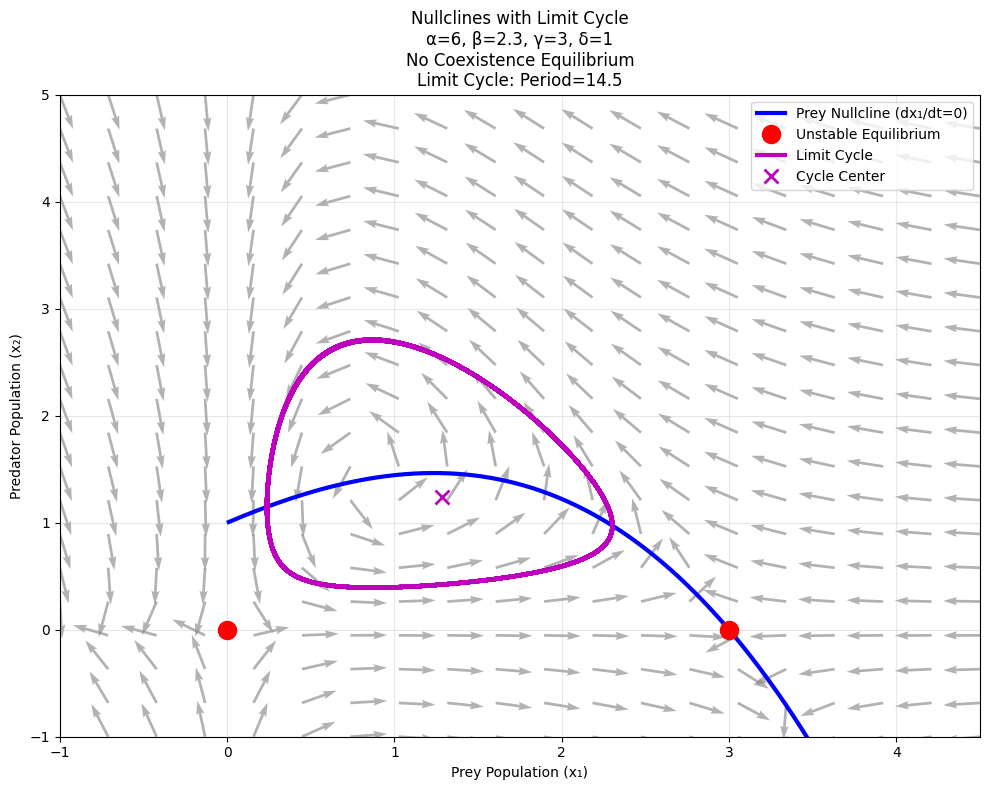

α=6, β=2.3: No Coexistence Equilibrium
  Limit cycle period: 14.48
--------------------------------------------------


In [37]:
def plot_nullclines_with_limit_cycles(alpha, beta, gamma, delta, x1_range=None, x2_range=None, t_span=(0, 3000)):
    """Plot nullclines with limit cycles if they exist"""
    
    if x1_range is None:
        x1_range = [-1, gamma * 1.5]
    if x2_range is None:
        x2_range = [-1, 5]
    
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Generate x1 values for plotting
    x1_vals = np.linspace(max(0.01, x1_range[0]), x1_range[1], 1000)
    
    # Plot prey nullcline (dx1/dt = 0)
    x2_prey = prey_nullcline(x1_vals, alpha, beta, gamma, delta)
    ax.plot(x1_vals, x2_prey, 'b-', linewidth=3, label='Prey Nullcline (dx₁/dt=0)')
    
    # Plot predator nullcline (dx2/dt = 0)
    predator_x1 = find_predator_nullcline_x1(alpha, beta)
    if predator_x1 is not None and predator_x1 <= x1_range[1]:
        ax.axvline(x=predator_x1, color='r', linestyle='-', linewidth=3, 
                  label='Predator Nullcline (dx₂/dt=0)')
    
    # Find and plot equilibria
    eq_points = find_equilibria(alpha, beta, gamma, delta)
    
    stable_eq, unstable_eq = [], []
    for eq in eq_points:
        if eq[0] >= 0 and eq[1] >= 0:
            J = jacobian(eq[0], eq[1], alpha, beta, gamma, delta)
            eigenvalues = eig(J)[0]
            real_parts = eigenvalues.real
            
            if all(real_parts < 0):
                stable_eq.append(eq)
                ax.plot(eq[0], eq[1], 'go', markersize=12, markerfacecolor='green', 
                       markeredgewidth=2, label='Stable Equilibrium')
            else:
                unstable_eq.append(eq)
                ax.plot(eq[0], eq[1], 'ro', markersize=12, markerfacecolor='red', 
                       markeredgewidth=2, label='Unstable Equilibrium')
    
    # Detect and plot limit cycle
    lc_info = detect_limit_cycle(alpha, beta, gamma, delta, t_span=t_span)
    
    if lc_info['exists']:
        x1_lc, x2_lc = lc_info['final_trajectory']
        ax.plot(x1_lc, x2_lc, 'm-', linewidth=3, label='Limit Cycle')
        
        # Plot the center of the limit cycle
        center_x1, center_x2 = lc_info['center']
        ax.plot(center_x1, center_x2, 'mx', markersize=10, markeredgewidth=2,
               label='Cycle Center')
        
        # Add limit cycle info to title
        cycle_info = f"Limit Cycle: Period={lc_info.get('period', 'N/A'):.1f}"
    else:
        cycle_info = "No Limit Cycle"
    
    # Plot vector field
    x1_grid = np.linspace(x1_range[0], x1_range[1], 20)
    x2_grid = np.linspace(x2_range[0], x2_range[1], 20)
    X1, X2 = np.meshgrid(x1_grid, x2_grid)
    
    U, V = np.zeros(X1.shape), np.zeros(X2.shape)
    for i in range(len(x1_grid)):
        for j in range(len(x2_grid)):
            derivatives = predator_prey(0, [X1[i,j], X2[i,j]], alpha, beta, gamma, delta)
            U[i,j] = derivatives[0]
            V[i,j] = derivatives[1]
    
    # Normalize arrows for better visualization
    magnitude = np.sqrt(U**2 + V**2)
    U_norm = np.where(magnitude > 0, U/magnitude, 0)
    V_norm = np.where(magnitude > 0, V/magnitude, 0)
    
    ax.quiver(X1, X2, U_norm, V_norm, color='gray', alpha=0.6, scale=25)
    
    # Bifurcation analysis
    bifurcation_info = analyze_bifurcation_from_nullclines(alpha, beta, gamma, delta, eq_points)
    
    ax.set_xlabel('Prey Population (x₁)')
    ax.set_ylabel('Predator Population (x₂)')
    ax.set_title(f'Nullclines with Limit Cycle\nα={alpha}, β={beta}, γ={gamma}, δ={delta}\n{bifurcation_info}\n{cycle_info}')
    ax.set_xlim(x1_range)
    ax.set_ylim(x2_range)
    ax.grid(True, alpha=0.3)
    
    # Remove duplicate labels in legend
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(), loc='upper right')
    
    plt.tight_layout()
    plt.show()
    
    return lc_info, bifurcation_info

# Test with parameters that give limit cycles
limit_cycle_params = [
    (2, 3.2, 3, 1),    # Strong limit cycle
    (4, 2.6, 3, 1),    # Moderate limit cycle
    (6, 2.3, 3, 1),    # Another limit cycle
]

for alpha, beta, gamma, delta in limit_cycle_params:
    lc_info, bif_info = plot_nullclines_with_limit_cycles(alpha, beta, gamma, delta)
    print(f"α={alpha}, β={beta}: {bif_info}")
    if lc_info['exists']:
        print(f"  Limit cycle period: {lc_info.get('period', 'N/A'):.2f}")
    print("-" * 50)

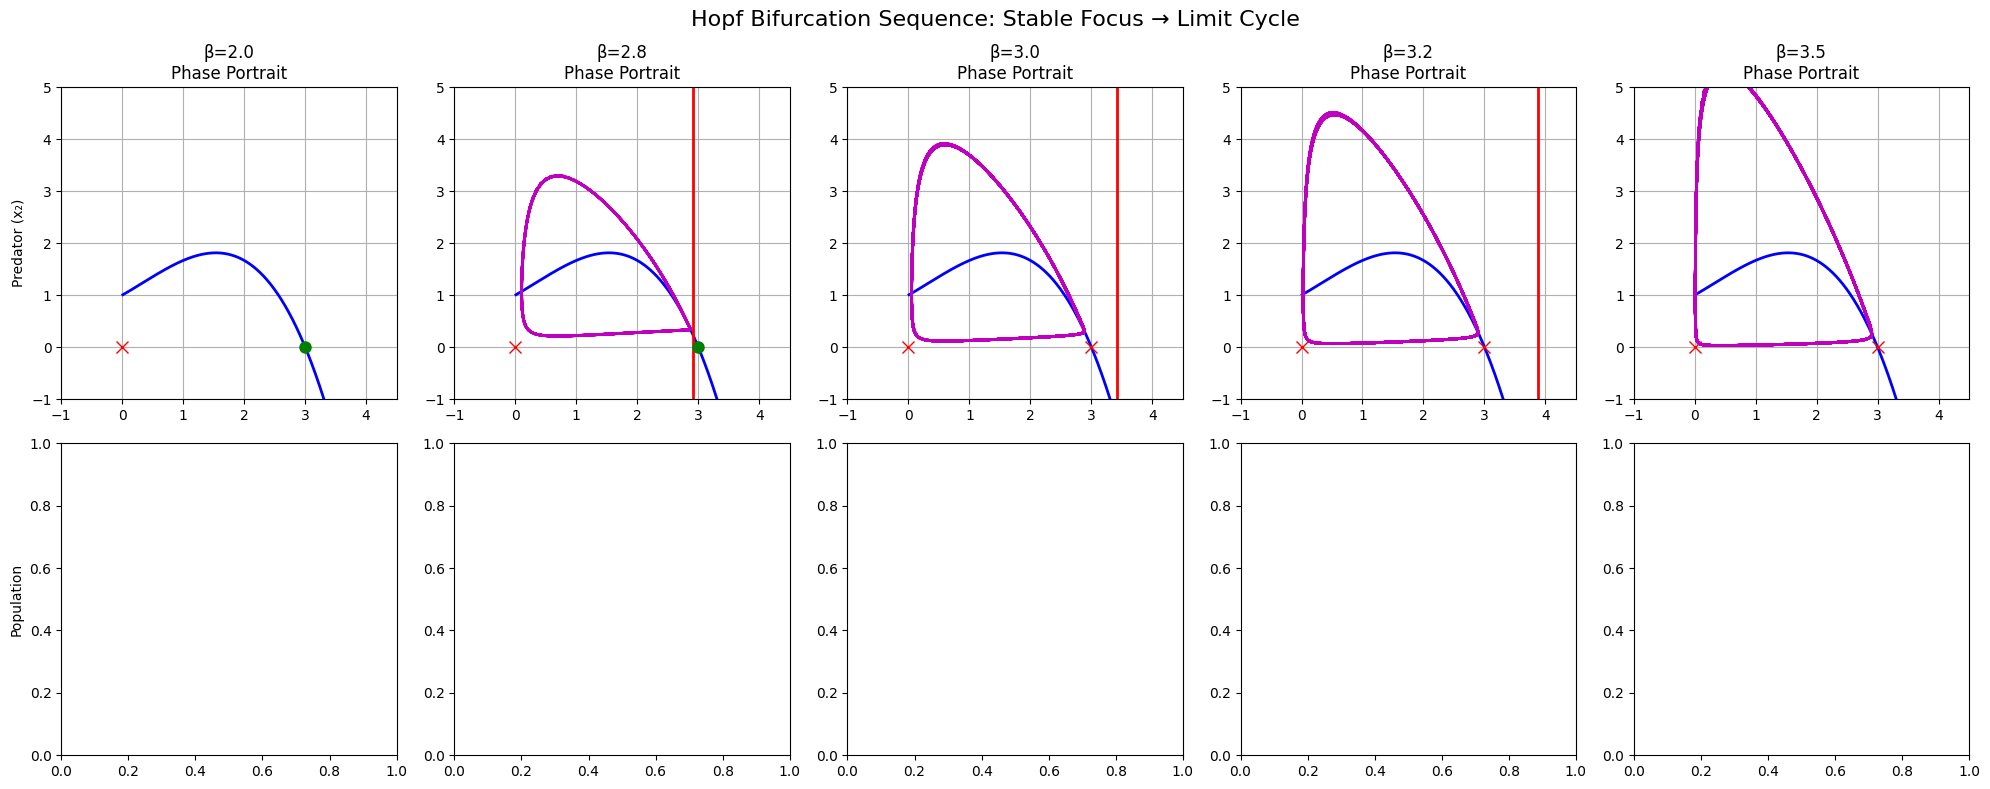

In [40]:
def plot_hopf_bifurcation_sequence():
    """Show the complete Hopf bifurcation sequence with nullclines and limit cycles"""
    
    # Parameter sequence showing Hopf bifurcation
    beta_sequence = [2.0, 2.8, 3.0, 3.2, 3.5]  # Stable → Hopf → Limit cycle
    alpha, gamma, delta = 2, 3, 1
    
    fig, axes = plt.subplots(2, len(beta_sequence), figsize=(20, 8))
    
    for i, beta in enumerate(beta_sequence):
        # Top row: Phase portrait with nullclines
        x1_range = [-1, gamma * 1.5]
        x2_range = [-1, 5]
        
        x1_vals = np.linspace(0.01, x1_range[1], 1000)
        
        # Prey nullcline
        x2_prey = prey_nullcline(x1_vals, alpha, beta, gamma, delta)
        axes[0,i].plot(x1_vals, x2_prey, 'b-', linewidth=2)
        
        # Predator nullcline
        predator_x1 = find_predator_nullcline_x1(alpha, beta)
        if predator_x1 is not None:
            axes[0,i].axvline(x=predator_x1, color='r', linestyle='-', linewidth=2)
        
        # Equilibria
        eq_points = find_equilibria(alpha, beta, gamma, delta)
        for eq in eq_points:
            if eq[0] >= 0 and eq[1] >= 0:
                J = jacobian(eq[0], eq[1], alpha, beta, gamma, delta)
                eigenvalues = eig(J)[0]
                real_parts = eigenvalues.real
                
                color = 'green' if all(real_parts < 0) else 'red'
                marker = 'o' if all(real_parts < 0) else 'x'
                axes[0,i].plot(eq[0], eq[1], marker, color=color, markersize=8, 
                              markerfacecolor=color)
        
        # Limit cycle
        lc_info = detect_limit_cycle(alpha, beta, gamma, delta, t_span=(0, 3000))
        if lc_info['exists']:
            x1_lc, x2_lc = lc_info['final_trajectory']
            axes[0,i].plot(x1_lc, x2_lc, 'm-', linewidth=2)
        
        axes[0,i].set_xlim(x1_range)
        axes[0,i].set_ylim(x2_range)
        axes[0,i].set_title(f'β={beta}\nPhase Portrait')
        axes[0,i].grid(True)
        
        # Bottom row: Time series
        if len(eq_points) > 2:
            x0 = [eq_points[2][0]*1.1, eq_points[2][1]*1.1]
            t_span = (0, 200)
            t_eval = np.linspace(0, 200, 1000)
            
            sol = solve_ivp(predator_prey, t_span, x0, 
                           args=(alpha, beta, gamma, delta),
                           t_eval=t_eval, method='LSODA')
            
            axes[1,i].plot(sol.t, sol.y[0], 'b-', label='Prey')
            axes[1,i].plot(sol.t, sol.y[1], 'r-', label='Predator')
            axes[1,i].set_xlabel('Time')
            axes[1,i].set_ylabel('Population')
            axes[1,i].legend()
            axes[1,i].grid(True)
            axes[1,i].set_title('Time Series')
    
    # Add column labels
    axes[0,0].set_ylabel('Predator (x₂)')
    axes[1,0].set_ylabel('Population')
    
    plt.suptitle('Hopf Bifurcation Sequence: Stable Focus → Limit Cycle', fontsize=16)
    plt.tight_layout()
    plt.show()

# Plot the complete bifurcation sequence
plot_hopf_bifurcation_sequence()

Varying β parameter:


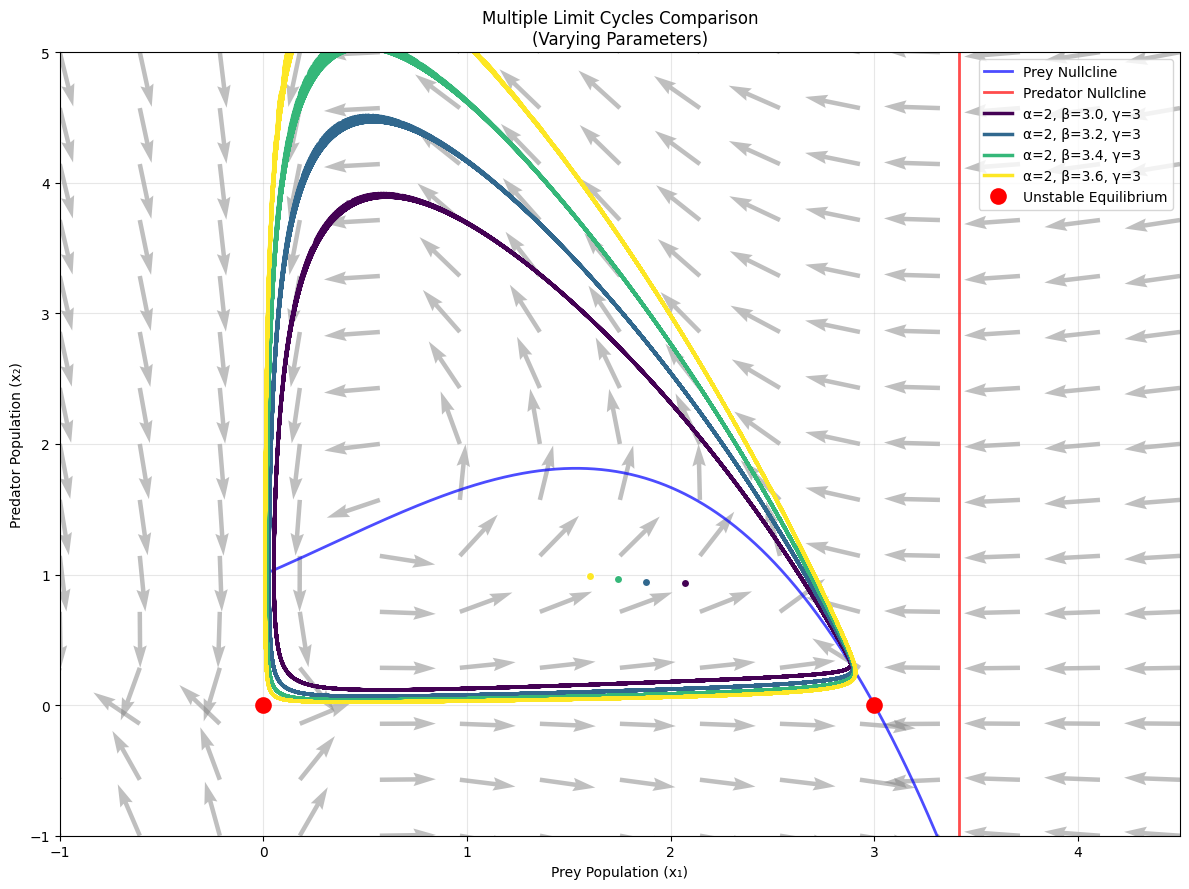

=== LIMIT CYCLE SUMMARY ===
α=2, β=3.0, γ=3, δ=1:
  Period: 35.12
  Amplitude: Prey=2.833, Predator=3.803
  Center: (2.068, 0.937)

α=2, β=3.2, γ=3, δ=1:
  Period: 27.76
  Amplitude: Prey=2.867, Predator=4.450
  Center: (1.878, 0.941)

α=2, β=3.4, γ=3, δ=1:
  Period: 24.79
  Amplitude: Prey=2.887, Predator=5.066
  Center: (1.740, 0.968)

α=2, β=3.6, γ=3, δ=1:
  Period: 23.29
  Amplitude: Prey=2.899, Predator=5.664
  Center: (1.602, 0.986)


Varying α parameter:


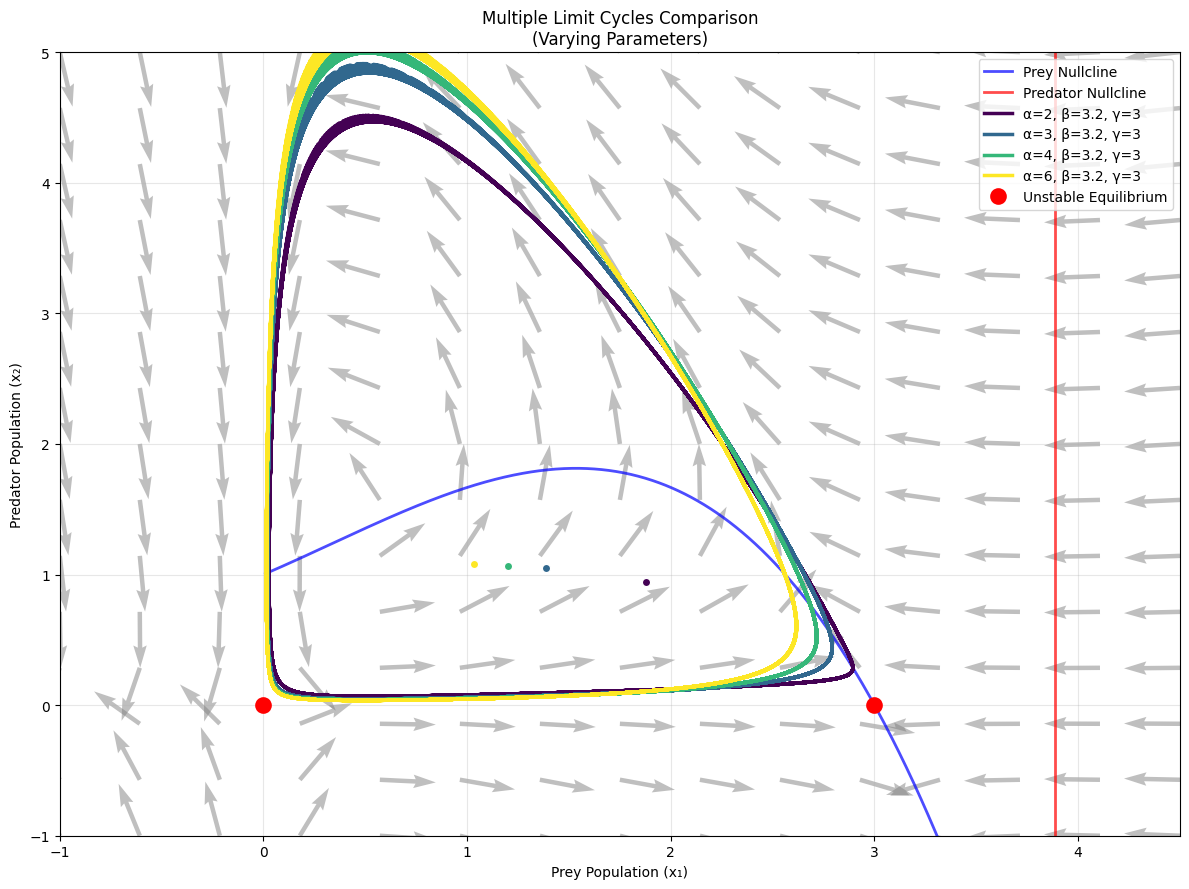

=== LIMIT CYCLE SUMMARY ===
α=2, β=3.2, γ=3, δ=1:
  Period: 27.76
  Amplitude: Prey=2.867, Predator=4.450
  Center: (1.878, 0.941)

α=3, β=3.2, γ=3, δ=1:
  Period: 18.07
  Amplitude: Prey=2.774, Predator=4.866
  Center: (1.388, 1.052)

α=4, β=3.2, γ=3, δ=1:
  Period: 16.04
  Amplitude: Prey=2.702, Predator=5.039
  Center: (1.202, 1.063)

α=6, β=3.2, γ=3, δ=1:
  Period: 14.59
  Amplitude: Prey=2.604, Predator=5.161
  Center: (1.032, 1.078)


Varying γ parameter:
No limit cycle for α=2, β=3.2, γ=4, δ=1
No limit cycle for α=2, β=3.2, γ=5, δ=1


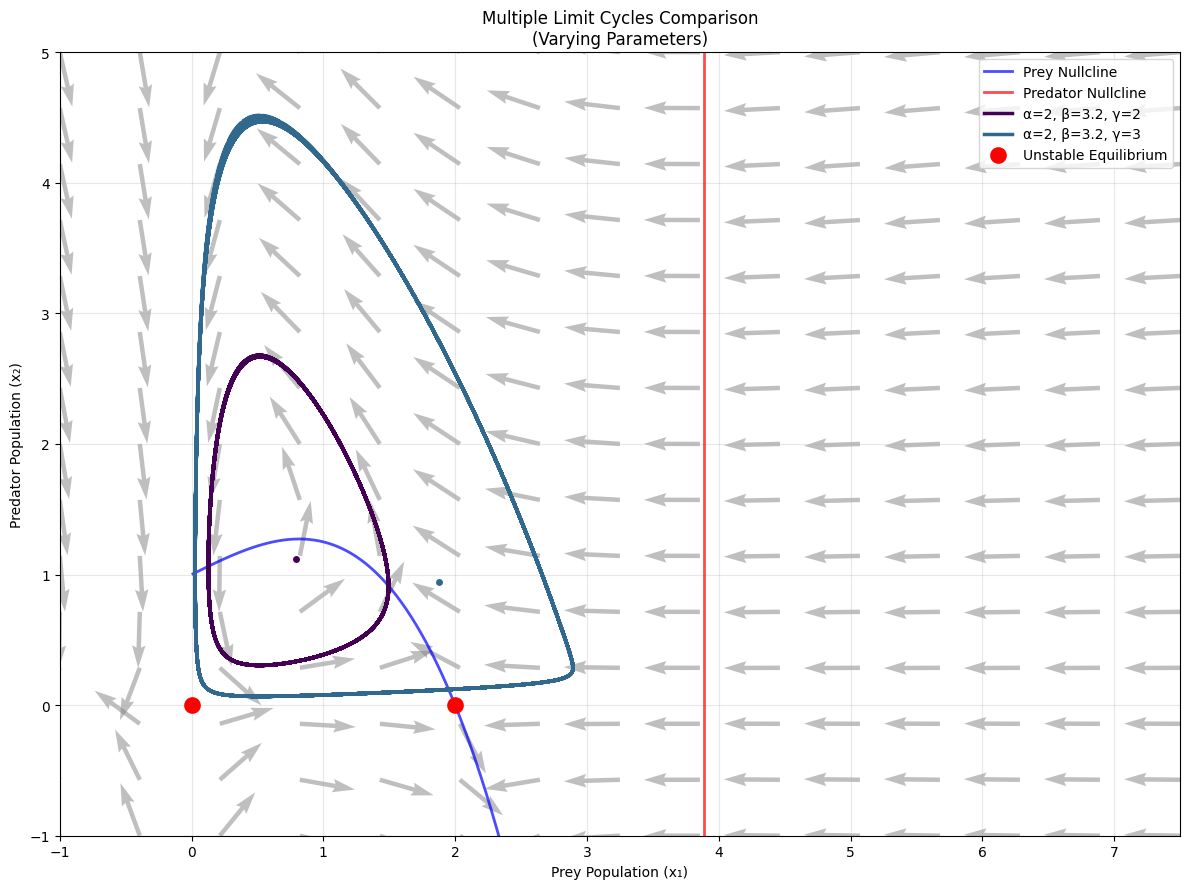

=== LIMIT CYCLE SUMMARY ===
α=2, β=3.2, γ=2, δ=1:
  Period: 13.23
  Amplitude: Prey=1.369, Predator=2.376
  Center: (0.789, 1.119)

α=2, β=3.2, γ=3, δ=1:
  Period: 27.76
  Amplitude: Prey=2.867, Predator=4.450
  Center: (1.878, 0.941)



In [44]:
def plot_multiple_limit_cycles_same_graph(parameter_sets, x1_range=None, x2_range=None, t_span=(0, 3000)):
    """Plot multiple limit cycles on the same graph for comparison"""
    
    if x1_range is None:
        # Find maximum gamma to set appropriate x-range
        max_gamma = max(params[2] for params in parameter_sets)
        x1_range = [-1, max_gamma * 1.5]
    if x2_range is None:
        x2_range = [-1, 5]
    
    fig, ax = plt.subplots(figsize=(12, 9))
    
    # Create a color map for different limit cycles
    colors = plt.cm.viridis(np.linspace(0, 1, len(parameter_sets)))
    
    # Plot nullclines for reference (using first parameter set)
    alpha_ref, beta_ref, gamma_ref, delta_ref = parameter_sets[0]
    x1_vals = np.linspace(max(0.01, x1_range[0]), x1_range[1], 1000)
    
    # Prey nullcline
    x2_prey = prey_nullcline(x1_vals, alpha_ref, beta_ref, gamma_ref, delta_ref)
    ax.plot(x1_vals, x2_prey, 'b-', linewidth=2, alpha=0.7, label='Prey Nullcline')
    
    # Predator nullcline
    predator_x1 = find_predator_nullcline_x1(alpha_ref, beta_ref)
    if predator_x1 is not None and predator_x1 <= x1_range[1]:
        ax.axvline(x=predator_x1, color='r', linestyle='-', linewidth=2, alpha=0.7, 
                  label='Predator Nullcline')
    
    # Plot each limit cycle
    limit_cycle_info = []
    
    for i, (alpha, beta, gamma, delta) in enumerate(parameter_sets):
        # Detect limit cycle
        lc_info = detect_limit_cycle(alpha, beta, gamma, delta, t_span=t_span)
        
        if lc_info['exists']:
            x1_lc, x2_lc = lc_info['final_trajectory']
            
            # Plot limit cycle
            ax.plot(x1_lc, x2_lc, color=colors[i], linewidth=2.5, 
                   label=f'α={alpha}, β={beta}, γ={gamma}')
            
            # Plot cycle center
            center_x1, center_x2 = lc_info['center']
            ax.plot(center_x1, center_x2, 'o', color=colors[i], markersize=6,
                   markerfacecolor=colors[i], markeredgecolor='white')
            
            limit_cycle_info.append({
                'params': (alpha, beta, gamma, delta),
                'info': lc_info,
                'color': colors[i]
            })
        else:
            print(f"No limit cycle for α={alpha}, β={beta}, γ={gamma}, δ={delta}")
    
    # Plot equilibria for reference (using first parameter set)
    eq_points = find_equilibria(alpha_ref, beta_ref, gamma_ref, delta_ref)
    for eq in eq_points:
        if eq[0] >= 0 and eq[1] >= 0:
            J = jacobian(eq[0], eq[1], alpha_ref, beta_ref, gamma_ref, delta_ref)
            eigenvalues = eig(J)[0]
            real_parts = eigenvalues.real
            
            if all(real_parts < 0):
                ax.plot(eq[0], eq[1], 'go', markersize=10, markerfacecolor='green', 
                       markeredgewidth=2, label='Stable Equilibrium')
            else:
                ax.plot(eq[0], eq[1], 'ro', markersize=10, markerfacecolor='red', 
                       markeredgewidth=2, label='Unstable Equilibrium')
    
    # Add vector field for context
    x1_grid = np.linspace(x1_range[0], x1_range[1], 15)
    x2_grid = np.linspace(x2_range[0], x2_range[1], 15)
    X1, X2 = np.meshgrid(x1_grid, x2_grid)
    
    U, V = np.zeros(X1.shape), np.zeros(X2.shape)
    for i in range(len(x1_grid)):
        for j in range(len(x2_grid)):
            derivatives = predator_prey(0, [X1[i,j], X2[i,j]], alpha_ref, beta_ref, gamma_ref, delta_ref)
            U[i,j] = derivatives[0]
            V[i,j] = derivatives[1]
    
    # Normalize arrows
    magnitude = np.sqrt(U**2 + V**2)
    U_norm = np.where(magnitude > 0, U/magnitude, 0)
    V_norm = np.where(magnitude > 0, V/magnitude, 0)
    
    ax.quiver(X1, X2, U_norm, V_norm, color='gray', alpha=0.5, scale=20)
    
    ax.set_xlabel('Prey Population (x₁)')
    ax.set_ylabel('Predator Population (x₂)')
    ax.set_title('Multiple Limit Cycles Comparison\n(Varying Parameters)')
    ax.set_xlim(x1_range)
    ax.set_ylim(x2_range)
    ax.grid(True, alpha=0.3)
    
    # Create legend without duplicates
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(), loc='upper right')
    
    plt.tight_layout()
    plt.show()
    
    # Print summary information
    print("=== LIMIT CYCLE SUMMARY ===")
    for info in limit_cycle_info:
        alpha, beta, gamma, delta = info['params']
        lc = info['info']
        print(f"α={alpha}, β={beta}, γ={gamma}, δ={delta}:")
        print(f"  Period: {lc.get('period', 'N/A'):.2f}")
        print(f"  Amplitude: Prey={lc['amplitude'][0]:.3f}, Predator={lc['amplitude'][1]:.3f}")
        print(f"  Center: ({lc['center'][0]:.3f}, {lc['center'][1]:.3f})")
        print()
    
    return limit_cycle_info

# Example 1: Varying beta with fixed other parameters
parameter_sets_beta = [
    (2, 3.0, 3, 1),   # Small limit cycle
    (2, 3.2, 3, 1),   # Medium limit cycle
    (2, 3.4, 3, 1),   # Large limit cycle
    (2, 3.6, 3, 1),   # Very large limit cycle
]

print("Varying β parameter:")
lc_info_beta = plot_multiple_limit_cycles_same_graph(parameter_sets_beta)

# Example 2: Varying alpha with fixed beta
parameter_sets_alpha = [
    (2, 3.2, 3, 1),   # Reference
    (3, 3.2, 3, 1),   # Higher alpha
    (4, 3.2, 3, 1),   # Even higher alpha
    (6, 3.2, 3, 1),   # Highest alpha
]

print("\nVarying α parameter:")
lc_info_alpha = plot_multiple_limit_cycles_same_graph(parameter_sets_alpha)

# Example 3: Varying gamma with fixed other parameters
parameter_sets_gamma = [
    (2, 3.2, 2, 1),   # Low carrying capacity
    (2, 3.2, 3, 1),   # Medium carrying capacity
    (2, 3.2, 4, 1),   # High carrying capacity
    (2, 3.2, 5, 1),   # Very high carrying capacity
]

print("\nVarying γ parameter:")
lc_info_gamma = plot_multiple_limit_cycles_same_graph(parameter_sets_gamma)

Hopf Bifurcation Family (Varying β):


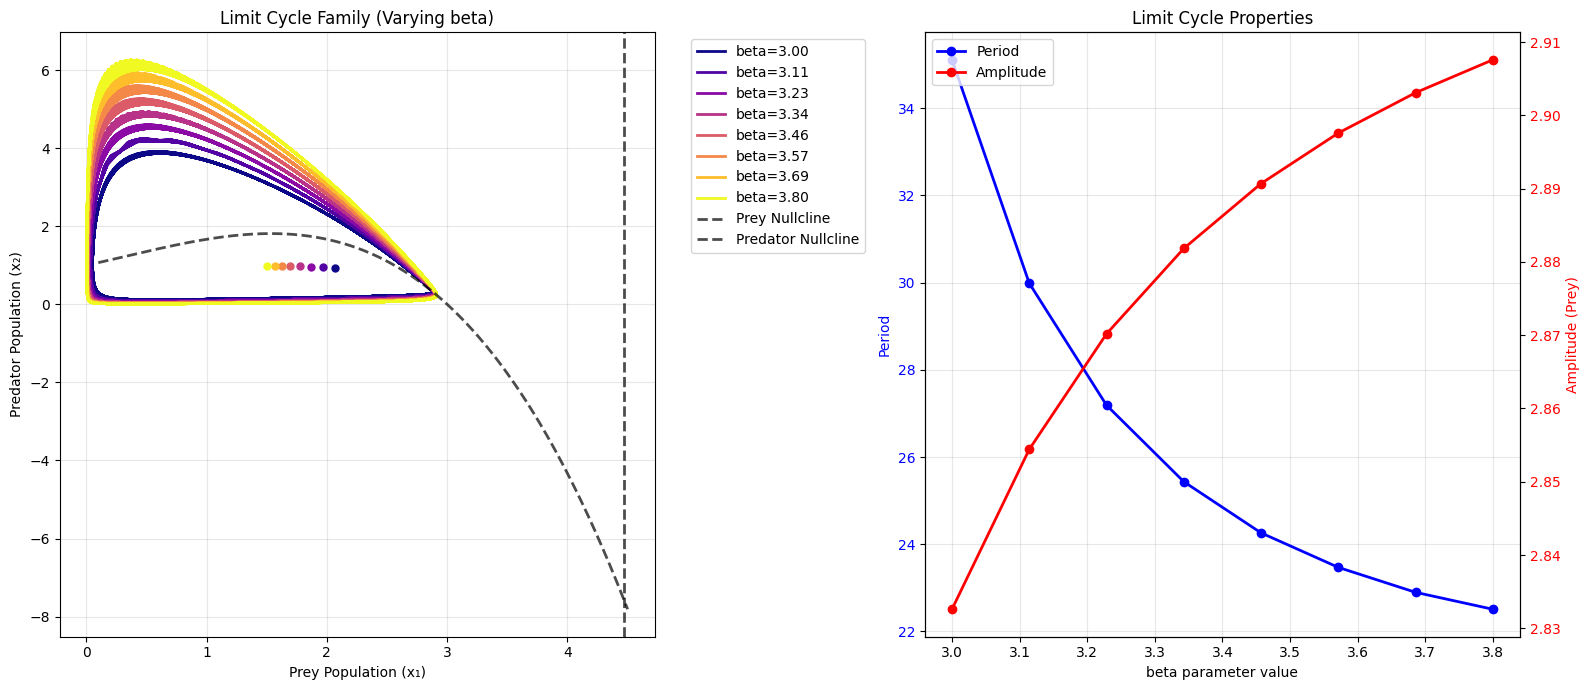


Varying α Family:


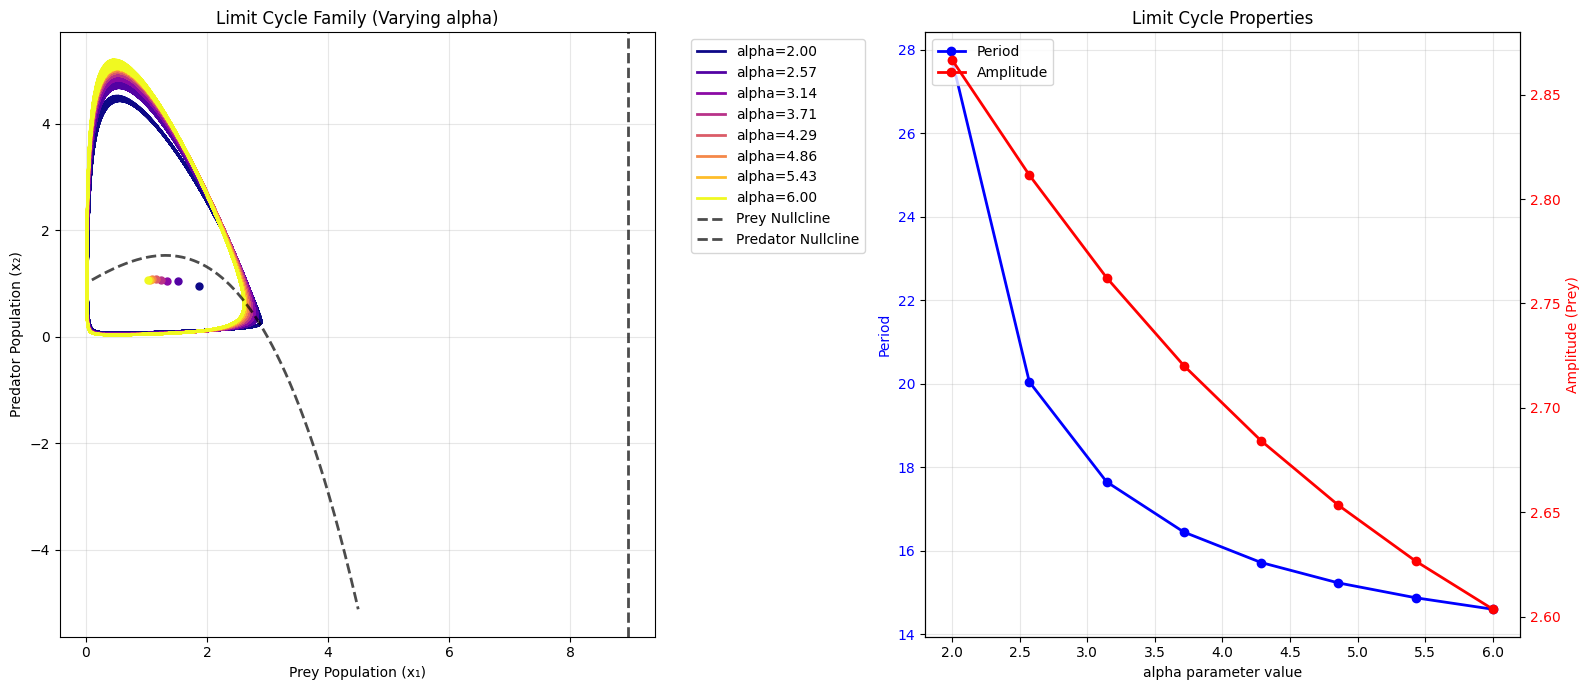

In [45]:
def plot_limit_cycle_family(param_name, param_values, fixed_params, t_span=(0, 4000)):
    """Plot a family of limit cycles showing evolution through Hopf bifurcation"""
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
    
    # Create color gradient
    colors = plt.cm.plasma(np.linspace(0, 1, len(param_values)))
    
    all_cycles_info = []
    
    for i, param_val in enumerate(param_values):
        params = fixed_params.copy()
        params[param_name] = param_val
        
        alpha = params.get('alpha', 2)
        beta = params.get('beta', 1.5)
        gamma = params.get('gamma', 3)
        delta = params.get('delta', 1)
        
        # Detect limit cycle
        lc_info = detect_limit_cycle(alpha, beta, gamma, delta, t_span=t_span)
        
        if lc_info['exists']:
            x1_lc, x2_lc = lc_info['final_trajectory']
            
            # Plot limit cycle
            ax1.plot(x1_lc, x2_lc, color=colors[i], linewidth=2, 
                    label=f'{param_name}={param_val:.2f}')
            
            # Plot center
            ax1.plot(lc_info['center'][0], lc_info['center'][1], 'o', 
                    color=colors[i], markersize=5)
            
            all_cycles_info.append({
                'param_value': param_val,
                'info': lc_info,
                'color': colors[i]
            })
    
    # Add nullclines for reference (using middle parameter value)
    mid_idx = len(param_values) // 2
    mid_param = param_values[mid_idx]
    params = fixed_params.copy()
    params[param_name] = mid_param
    
    alpha = params.get('alpha', 2)
    beta = params.get('beta', 1.5)
    gamma = params.get('gamma', 3)
    delta = params.get('delta', 1)
    
    # Plot prey nullcline
    x1_vals = np.linspace(0.1, gamma * 1.5, 1000)
    x2_prey = prey_nullcline(x1_vals, alpha, beta, gamma, delta)
    ax1.plot(x1_vals, x2_prey, 'k--', linewidth=2, alpha=0.7, label='Prey Nullcline')
    
    # Plot predator nullcline
    predator_x1 = find_predator_nullcline_x1(alpha, beta)
    if predator_x1 is not None:
        ax1.axvline(x=predator_x1, color='k', linestyle='--', linewidth=2, alpha=0.7, 
                   label='Predator Nullcline')
    
    ax1.set_xlabel('Prey Population (x₁)')
    ax1.set_ylabel('Predator Population (x₂)')
    ax1.set_title(f'Limit Cycle Family (Varying {param_name})')
    ax1.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax1.grid(True, alpha=0.3)
    
    # Plot properties vs parameter
    if all_cycles_info:
        param_vals = [info['param_value'] for info in all_cycles_info]
        periods = [info['info'].get('period', np.nan) for info in all_cycles_info]
        amplitudes = [info['info']['amplitude'][0] for info in all_cycles_info]  # Prey amplitude
        
        ax2.plot(param_vals, periods, 'o-', color='blue', linewidth=2, markersize=6, label='Period')
        ax2.set_xlabel(f'{param_name} parameter value')
        ax2.set_ylabel('Period', color='blue')
        ax2.tick_params(axis='y', labelcolor='blue')
        ax2.grid(True, alpha=0.3)
        
        ax2_twin = ax2.twinx()
        ax2_twin.plot(param_vals, amplitudes, 'o-', color='red', linewidth=2, markersize=6, label='Amplitude')
        ax2_twin.set_ylabel('Amplitude (Prey)', color='red')
        ax2_twin.tick_params(axis='y', labelcolor='red')
        
        ax2.set_title('Limit Cycle Properties')
        # Combine legends
        lines1, labels1 = ax2.get_legend_handles_labels()
        lines2, labels2 = ax2_twin.get_legend_handles_labels()
        ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
    
    plt.tight_layout()
    plt.show()
    
    return all_cycles_info

# Plot limit cycle families for different parameters
fixed_params = {'alpha': 2, 'gamma': 3, 'delta': 1}

# Varying beta through Hopf bifurcation
beta_values = np.linspace(3.0, 3.8, 8)  # Through Hopf bifurcation
print("Hopf Bifurcation Family (Varying β):")
lc_family_beta = plot_limit_cycle_family('beta', beta_values, fixed_params)

# Varying alpha
alpha_values = np.linspace(2, 6, 8)
print("\nVarying α Family:")
lc_family_alpha = plot_limit_cycle_family('alpha', alpha_values, {'beta': 3.2, 'gamma': 3, 'delta': 1})

3D Limit Cycle Comparison:


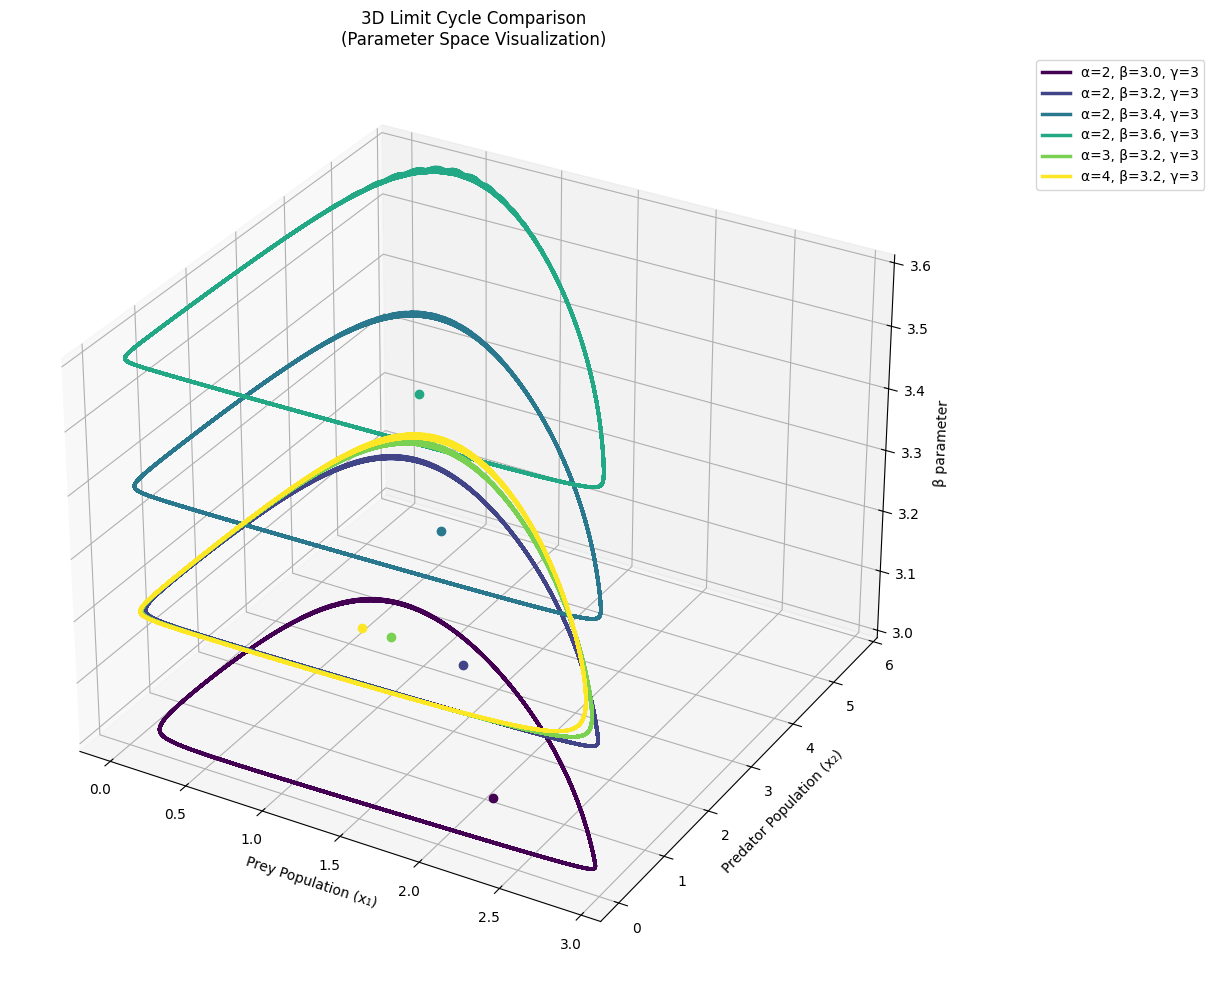

In [46]:
def plot_3d_limit_cycle_comparison(parameter_sets, t_span=(0, 3000)):
    """3D plot showing limit cycles with parameter as third dimension"""
    
    from mpl_toolkits.mplot3d import Axes3D
    
    fig = plt.figure(figsize=(14, 10))
    
    # Create 3D plot
    ax = fig.add_subplot(111, projection='3d')
    
    # Choose parameter to use as z-axis (using beta as default)
    z_param = 'beta'
    colors = plt.cm.viridis(np.linspace(0, 1, len(parameter_sets)))
    
    for i, (alpha, beta, gamma, delta) in enumerate(parameter_sets):
        lc_info = detect_limit_cycle(alpha, beta, gamma, delta, t_span=t_span)
        
        if lc_info['exists']:
            x1_lc, x2_lc = lc_info['final_trajectory']
            
            # Create z-values (using the chosen parameter)
            if z_param == 'beta':
                z_vals = np.full_like(x1_lc, beta)
                z_label = 'β parameter'
            elif z_param == 'alpha':
                z_vals = np.full_like(x1_lc, alpha)
                z_label = 'α parameter'
            elif z_param == 'gamma':
                z_vals = np.full_like(x1_lc, gamma)
                z_label = 'γ parameter'
            else:
                z_vals = np.full_like(x1_lc, delta)
                z_label = 'δ parameter'
            
            # Plot 3D limit cycle
            ax.plot(x1_lc, x2_lc, z_vals, color=colors[i], linewidth=2.5,
                   label=f'α={alpha}, β={beta}, γ={gamma}')
            
            # Plot center point
            ax.plot([lc_info['center'][0]], [lc_info['center'][1]], [z_vals[0]], 
                   'o', color=colors[i], markersize=6)
    
    ax.set_xlabel('Prey Population (x₁)')
    ax.set_ylabel('Predator Population (x₂)')
    ax.set_zlabel(z_label)
    ax.set_title('3D Limit Cycle Comparison\n(Parameter Space Visualization)')
    
    # Add legend
    ax.legend(bbox_to_anchor=(1.1, 1), loc='upper left')
    
    plt.tight_layout()
    plt.show()

# 3D comparison of limit cycles
parameter_sets_3d = [
    (2, 3.0, 3, 1),
    (2, 3.2, 3, 1),
    (2, 3.4, 3, 1),
    (2, 3.6, 3, 1),
    (3, 3.2, 3, 1),
    (4, 3.2, 3, 1),
]

print("3D Limit Cycle Comparison:")
plot_3d_limit_cycle_comparison(parameter_sets_3d)